# **Проектная работа №4. Анализ динамики изменений земного покрова на последовательности разновременных спутниковых снимков с использованием спектральных индексов**

## **1. Цель работы**

Выполнить количественный анализ динамики изменения классов земного покрова на выбранной территории за период с 2019 по 2024 год на основе разновременных спутниковых снимков Sentinel-2 и провести сравнительную оценку результатов, полученных методом пороговой сегментации на основе спектральных индексов и с использованием готовых карт классификации Dynamic World.

## **2. Задачи работы**

1.  **Подготовить** последовательность разновременных снимков (снимки Sentinel-2 и карты Dynamic World) за 2019-2024 гг.;
2.  **Классифицировать** земной покров на снимках Sentinel-2, применив метод пороговой сегментации по спектральным индексам;
3.  **Рассчитать и сравнить** количественные показатели динамики (площади, темпы роста) для двух методов классификации: по индексам и по данным Dynamic World;
4.  **Оценить** выявленные тренды изменения покрова и **сформулировать** выводы о сопоставимости результатов двух методов анализа.

## **3. Загрузка данных для анализа из Google Earth Engine**

> **Примечание.** В качестве примера реализации можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/nWdJIg. Для выполнения текущей работы актуальны только **Раздел 1** и **Раздел 2** указанного источника.





### **3.1. Настройка рабочей среды и аутентификация**

In [1]:
%%capture
%pip install -q earthengine-api geemap geedim rasterio numpy pandas matplotlib

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import geometry_mask
from rasterio.transform import from_origin
from rasterio.warp import transform_bounds, transform_geom
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from IPython.display import display

YEARS = list(range(2019, 2025))
BANDS = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12']
SCALE = 10
NODATA = -9999
ROOT = Path('5_files')
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'
for folder in (DATA, RESULTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 100, 'font.size': 10,
                     'axes.titlesize': 12, 'axes.titleweight': 'bold'})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda value: f'{value:.2f}')

required_files = []
for year in YEARS:
    required_files.append(DATA / f'sentinel2_summer_{year}.tif')
    required_files.append(DATA / f'DYNAMICWORLD_summer_{year}.tif')

download_needed = False
for path in required_files:
    if not path.is_file():
        download_needed = True

if download_needed:
    import ee
    import geemap
    from google.oauth2.credentials import Credentials
    project_id = input('ID проекта Google Cloud с Earth Engine: ').strip()
    if not project_id:
        raise ValueError('Для загрузки данных нужен ID проекта Earth Engine.')
    # Подключение к Earth Engine.
    try:
        auth_arguments = ee.oauth.get_credentials_arguments()
    except FileNotFoundError:
        auth_arguments = {}
    if not auth_arguments.get('refresh_token'):
        ee.Authenticate(auth_mode='notebook', force=True,
                        scopes=['https://www.googleapis.com/auth/earthengine.readonly'])
        auth_arguments = ee.oauth.get_credentials_arguments()
    credentials = Credentials(token=None, **auth_arguments)
    ee.Initialize(credentials=credentials, project=project_id)
    print('Подключение к Earth Engine выполнено.')
else:
    print('Используются ранее загруженные GeoTIFF из 5_files/data.')


### **3.2. Определение области интереса**

- Выберите территорию размером не менее 10×10 км (100 км²) с разнообразным земным покровом
- Обязательно должны присутствовать: водные объекты, растительность, застройка, открытая почва
- Зафиксируйте координаты углов ROI для воспроизводимости результатов

In [3]:
# Клязьминское водохранилище, леса, поля и застройка севернее Москвы.
ROI_BOUNDS = [37.40, 55.92, 37.62, 56.04]
west, south, east, north = ROI_BOUNDS
ROI_COORDS = [[west, south], [east, south], [east, north],
              [west, north], [west, south]]
roi_geojson = {'type': 'Polygon', 'coordinates': [ROI_COORDS]}
# Для выбранного участка используется UTM 37N.
EXPORT_CRS = 'EPSG:32637'

# Общая сетка для всех лет и обоих методов.
left, bottom, right, top = transform_bounds(
    'EPSG:4326', EXPORT_CRS, *ROI_BOUNDS, densify_pts=21)
left = np.floor(left / SCALE) * SCALE
bottom = np.floor(bottom / SCALE) * SCALE
right = np.ceil(right / SCALE) * SCALE
top = np.ceil(top / SCALE) * SCALE
WIDTH = int(round((right - left) / SCALE))
HEIGHT = int(round((top - bottom) / SCALE))
GRID = from_origin(left, top, SCALE, SCALE)
GRID_TRANSFORM = [GRID.a, GRID.b, GRID.c, GRID.d, GRID.e, GRID.f]
roi_utm = transform_geom('EPSG:4326', EXPORT_CRS, roi_geojson)
roi_mask = geometry_mask([roi_utm], out_shape=(HEIGHT, WIDTH),
                         transform=GRID, invert=True)
roi_area_ha = roi_mask.sum() * SCALE ** 2 / 10000
extent_km = (0, WIDTH * SCALE / 1000, 0, HEIGHT * SCALE / 1000)

print('Углы ROI [долгота, широта]:', ROI_COORDS)
print('Проекция:', EXPORT_CRS)
print(f'Охват: около {(right-left)/1000:.1f} × {(top-bottom)/1000:.1f} км')
print(f'Площадь ROI по сетке: {roi_area_ha / 100:.2f} км²')
print(f'Пиксель: {SCALE} × {SCALE} м; сетка: {WIDTH} × {HEIGHT}')
roi = None
if download_needed:
    roi = ee.Geometry.Polygon([ROI_COORDS], geodesic=False)


Углы ROI [долгота, широта]: [[37.4, 55.92], [37.62, 55.92], [37.62, 56.04], [37.4, 56.04], [37.4, 55.92]]
Проекция: EPSG:32637
Охват: около 14.0 × 13.7 км
Площадь ROI по сетке: 183.38 км²
Пиксель: 10 × 10 м; сетка: 1402 × 1366


Все растры приведены к одной сетке 10×10 м в UTM. Каналы B11 и B12 с разрешением 20 м также пересчитаны на эту сетку.


### **3.3. Функции для загрузки и обработки данных Sentinel-2**

In [4]:
def load_sentinel2_collection(roi, start_date, end_date, cloud_percentage=20):
    collection = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    collection = collection.filterBounds(roi)
    collection = collection.filterDate(start_date, end_date)
    collection = collection.filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', cloud_percentage))

    def mask_clouds(image):
        scl = image.select('SCL')
        # Убираем пропуски, испорченные пиксели, облака и их тени.
        mask = scl.neq(0).And(scl.neq(1)).And(scl.neq(3))
        mask = mask.And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
        result = image.select(BANDS).updateMask(mask)
        result = result.divide(10000)
        return result.copyProperties(image, ['system:time_start', 'system:index'])

    return collection.map(mask_clouds)


def create_median_composite(collection, roi):
    median = collection.median()
    return median.clip(roi)


### **3.4. Создание медианных композитов за летние периоды 2019-2024**

- Используйте медиану для минимизации влияния облачности
- Фильтрация по облачности: CLOUDY_PIXEL_PERCENTAGE < 20%
- Маскирование облаков и теней по каналу SCL (см. лекцию, раздел 2.2)


In [5]:
sentinel_composites = {}
source_info = {'roi': roi_geojson, 'crs': EXPORT_CRS, 'scale_m': SCALE,
               'bands': BANDS, 'scl_excluded': [0, 1, 3, 8, 9, 10],
               'cloud_percentage_lt': 20, 'years': {}}
if download_needed:
    for year in YEARS:
        # Конечная дата не включается в период, поэтому берём 1 сентября.
        start = f'{year}-06-01'
        end = f'{year}-09-01'
        collection = load_sentinel2_collection(roi, start, end)
        image_ids = collection.aggregate_array('system:index').getInfo()
        if not image_ids:
            raise ValueError(f'Нет подходящих снимков Sentinel-2 за {year} год.')
        sentinel_composites[year] = create_median_composite(collection, roi)
        source_info['years'][str(year)] = {'sentinel2_images': image_ids,
                                          'start': start, 'end_exclusive': end}
        print(f'{year}: Sentinel-2 — {len(image_ids)} снимков')


2019: Sentinel-2 — 36 снимков
2020: Sentinel-2 — 19 снимков
2021: Sentinel-2 — 52 снимков
2022: Sentinel-2 — 27 снимков
2023: Sentinel-2 — 23 снимков
2024: Sentinel-2 — 41 снимков


### **3.5. Функции для загрузки и обработки данных карт классификации**

**Используйте коллекцию Dynamic World (Google/WRI)**

**Коллекция в GEE:** `ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")`
- **Период:** с июня 2015 года по настоящее время (обновляется постоянно)
- **Разрешение:** 10 метров
- **Особенности:**
  - Предоставляет вероятности для каждого класса (не жесткую классификацию)
  - Обновляется почти в реальном времени для каждого снимка Sentinel-2
  - 9 классов земного покрова


```python
# Пример загрузки Dynamic World

def load_landcover_data(roi, start_date, end_date, composite='mode'):
    """
    Загружает карты классификации Google Dynamic World (10м).
    
    Классы: 0-Вода, 1-Деревья, 2-Трава, 3-Затопл.растительность,
            4-Культуры, 5-Кустарники, 6-Застройка, 7-Голая земля, 8-Снег/лед
    
    Args:
        roi: область интереса
        start_date, end_date: период 'YYYY-MM-DD'
        composite: 'mode'|'first'|'mosaic'|'collection'
    """
    
    labels = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1") \
        .filterBounds(roi) \
        .filterDate(start_date, end_date) \
        .select('label')
    
    if composite == 'collection':
        return labels.map(lambda img: img.clip(roi))
    
    return getattr(labels, composite)().clip(roi)

# Загрузка с композитом по моде (наиболее частый класс)
landcover = load_landcover_data(roi, '2024-06-01', '2024-08-31')

# Параметры визуализации для Dynamic World
landcover_vis = {
    'min': 0,
    'max': 8,
    'palette': [
        '419bdf',  # 0 - Вода - синий
        '397d49',  # 1 - Деревья - темно-зеленый  
        '88b053',  # 2 - Трава - светло-зеленый
        '7a87c6',  # 3 - Затопленная растительность - сине-фиолетовый
        'e49635',  # 4 - Культуры - оранжево-желтый
        'dfc35a',  # 5 - Кустарники - песочный
        'c4281b',  # 6 - Застройка - красный
        'a59b8f',  # 7 - Голая земля - серо-коричневый
        'b39fe1'   # 8 - Снег и лед - светло-фиолетовый (для контраста)
    ]
}

# Визуализация на карте
map_dw = geemap.Map()
map_dw.centerObject(roi, 11)
map_dw.addLayer(landcover, landcover_vis, 'Dynamic World')
map_dw

```

In [6]:
DW_NAMES = ['Вода', 'Деревья', 'Трава', 'Затопленная растительность',
            'Культуры', 'Кустарники', 'Застройка', 'Голая земля', 'Снег и лед']
DW_COLORS = ['#419bdf', '#397d49', '#88b053', '#7a87c6', '#e49635',
             '#dfc35a', '#c4281b', '#a59b8f', '#b39fe1']


def load_landcover_data(roi, start_date, end_date, composite='mode'):
    labels = ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1')
    labels = labels.filterBounds(roi)
    labels = labels.filterDate(start_date, end_date)
    labels = labels.select('label')
    if composite == 'collection':
        return labels
    if composite != 'mode':
        raise ValueError('Для категориальных меток используется мода.')
    return labels.mode().toInt16().clip(roi)


### **3.6. Создание карт классификации за летние периоды 2019-2024**

- Для карт классов используйте моду — наиболее частый класс в каждом пикселе (`composite='mode'`): медиана номеров классов не имеет смысла

In [7]:
dw_composites = {}
if download_needed:
    for year in YEARS:
        start = f'{year}-06-01'
        end = f'{year}-09-01'
        labels = load_landcover_data(roi, start, end, composite='collection')
        image_ids = labels.aggregate_array('system:index').getInfo()
        if not image_ids:
            raise ValueError(f'Нет карт Dynamic World за {year} год.')
        dw_composites[year] = labels.mode().toInt16().clip(roi)
        source_info['years'][str(year)]['dynamic_world_images'] = image_ids
        print(f'{year}: Dynamic World — {len(image_ids)} карт')


2019: Dynamic World — 50 карт
2020: Dynamic World — 50 карт
2021: Dynamic World — 67 карт
2022: Dynamic World — 80 карт
2023: Dynamic World — 43 карт
2024: Dynamic World — 71 карт


### **3.7. Экспорт полученных растров**

- **Медианные композиты** Sentinel-2 (6 файлов GeoTIFF):
  - `sentinel2_summer_2019.tif` (июнь-август 2019)
  - `sentinel2_summer_2020.tif` (июнь-август 2020)
  - `sentinel2_summer_2021.tif` (июнь-август 2021)
  - `sentinel2_summer_2022.tif` (июнь-август 2022)
  - `sentinel2_summer_2023.tif` (июнь-август 2023)
  - `sentinel2_summer_2024.tif` (июнь-август 2024)

- **Карты классификации** Dynamic World (6 файлов GeoTIFF):
  - `DYNAMICWORLD_summer_2019.tif` (июнь-август 2019)
  - `DYNAMICWORLD_summer_2020.tif` (июнь-август 2020)
  - `DYNAMICWORLD_summer_2021.tif` (июнь-август 2021)
  - `DYNAMICWORLD_summer_2022.tif` (июнь-август 2022)
  - `DYNAMICWORLD_summer_2023.tif` (июнь-август 2023)
  - `DYNAMICWORLD_summer_2024.tif` (июнь-август 2024)

- Экспорт выполняйте в метрической проекции UTM функцией `export_georeferenced_raster` из лекции: размер пикселя 10×10 м
- Карты Dynamic World экспортируйте с типом `int16`: при типе `uint8` значение 0 используется как «нет данных» и совпадает с классом «Вода»
- Размер пикселя 10 м соответствует собственному разрешению каналов B2, B3, B4 и B8; каналы B11 и B12 (20 м) при экспорте пересчитываются на ту же сетку. Если экспорт идёт слишком долго, увеличьте `scale` (например, до 20 или 30 м): площади в разделе 6 рассчитываются по размеру пикселя из растра

In [11]:
from rasterio.warp import reproject
from rasterio.enums import Resampling


def align_raster_to_grid(filename):
    # Проверяем, совпадает ли растр с общей сеткой.
    with rasterio.open(filename) as src:
        same_size = src.shape == (HEIGHT, WIDTH)
        same_grid = src.transform.almost_equals(GRID)
        same_crs = src.crs == rasterio.crs.CRS.from_string(EXPORT_CRS)
        if same_size and same_grid and same_crs:
            return
        profile = src.profile.copy()
        descriptions = src.descriptions
        tags = src.tags()
        aligned = np.full((src.count, HEIGHT, WIDTH), NODATA, dtype=src.dtypes[0])
        reproject(source=src.read(), destination=aligned,
                  src_transform=src.transform, src_crs=src.crs,
                  src_nodata=src.nodata, dst_transform=GRID,
                  dst_crs=EXPORT_CRS, dst_nodata=NODATA,
                  resampling=Resampling.nearest)
    profile.update(height=HEIGHT, width=WIDTH, transform=GRID,
                   crs=EXPORT_CRS, nodata=NODATA)
    temporary = Path(filename).with_suffix('.aligned.tif')
    with rasterio.open(temporary, 'w', **profile) as dst:
        dst.write(aligned)
        dst.descriptions = descriptions
        dst.update_tags(**tags)
    temporary.replace(filename)


def export_georeferenced_raster(image, roi, filename, scale=SCALE,
                               dtype='float32', band_names=None):
    filename = Path(filename)
    if filename.is_file():
        align_raster_to_grid(filename)
        print('Уже сохранён:', filename.name)
        return filename
    if scale != SCALE:
        raise ValueError('Размер пикселя должен совпадать с общей сеткой.')
    temporary = filename.with_suffix('.partial.tif')
    geemap.download_ee_image(
        image=image, filename=str(temporary), region=roi,
        crs=EXPORT_CRS, crs_transform=GRID_TRANSFORM,
        shape=(HEIGHT, WIDTH), dtype=dtype, resampling='near',
        unmask_value=NODATA, max_tile_dim=512, max_tile_size=16, max_requests=4)

    # Для пропусков используем -9999, так как 0 означает воду.
    with rasterio.open(temporary) as src:
        values = src.read(masked=True).filled(NODATA).astype(dtype)
        profile = src.profile.copy()
    if dtype == 'float32':
        predictor = 3
    else:
        predictor = 2
    profile.update(nodata=NODATA, compress='deflate', predictor=predictor)
    with rasterio.open(filename, 'w', **profile) as dst:
        dst.write(values)
        if band_names is None:
            band_names = ['label']
        for number, name in enumerate(band_names, 1):
            dst.set_band_description(number, name)
        dst.update_tags(source='Google Earth Engine', summer='June-August')
    temporary.unlink()
    align_raster_to_grid(filename)
    print('Сохранён:', filename.name)
    return filename


if download_needed:
    for year in YEARS:
        export_georeferenced_raster(
            sentinel_composites[year], roi, DATA / f'sentinel2_summer_{year}.tif',
            dtype='float32', band_names=BANDS)
        export_georeferenced_raster(
            dw_composites[year], roi, DATA / f'DYNAMICWORLD_summer_{year}.tif',
            dtype='int16')
    (DATA / 'source_info.json').write_text(
        json.dumps(source_info, ensure_ascii=False, indent=2), encoding='utf-8')

print('Исходные GeoTIFF:', len(list(DATA.glob('*_summer_*.tif'))), 'из 12')


Уже сохранён: sentinel2_summer_2019.tif
Уже сохранён: DYNAMICWORLD_summer_2019.tif
Уже сохранён: sentinel2_summer_2020.tif
Уже сохранён: DYNAMICWORLD_summer_2020.tif
Уже сохранён: sentinel2_summer_2021.tif
Уже сохранён: DYNAMICWORLD_summer_2021.tif
Уже сохранён: sentinel2_summer_2022.tif
Уже сохранён: DYNAMICWORLD_summer_2022.tif
Уже сохранён: sentinel2_summer_2023.tif
Уже сохранён: DYNAMICWORLD_summer_2023.tif
Уже сохранён: sentinel2_summer_2024.tif
Уже сохранён: DYNAMICWORLD_summer_2024.tif
Исходные GeoTIFF: 12 из 12


## **4. Работа с загруженными растрами в RasterIO**

### **4.1. Загрузка и проверка растров**

,CRS,Размер,"Пиксель, м",Каналы,NoData
Год,,,,,
2019,EPSG:32637,1402 × 1366,10 × 10,6,-9999.00
2020,EPSG:32637,1402 × 1366,10 × 10,6,-9999.00
2021,EPSG:32637,1402 × 1366,10 × 10,6,-9999.00
2022,EPSG:32637,1402 × 1366,10 × 10,6,-9999.00
2023,EPSG:32637,1402 × 1366,10 × 10,6,-9999.00
2024,EPSG:32637,1402 × 1366,10 × 10,6,-9999.00


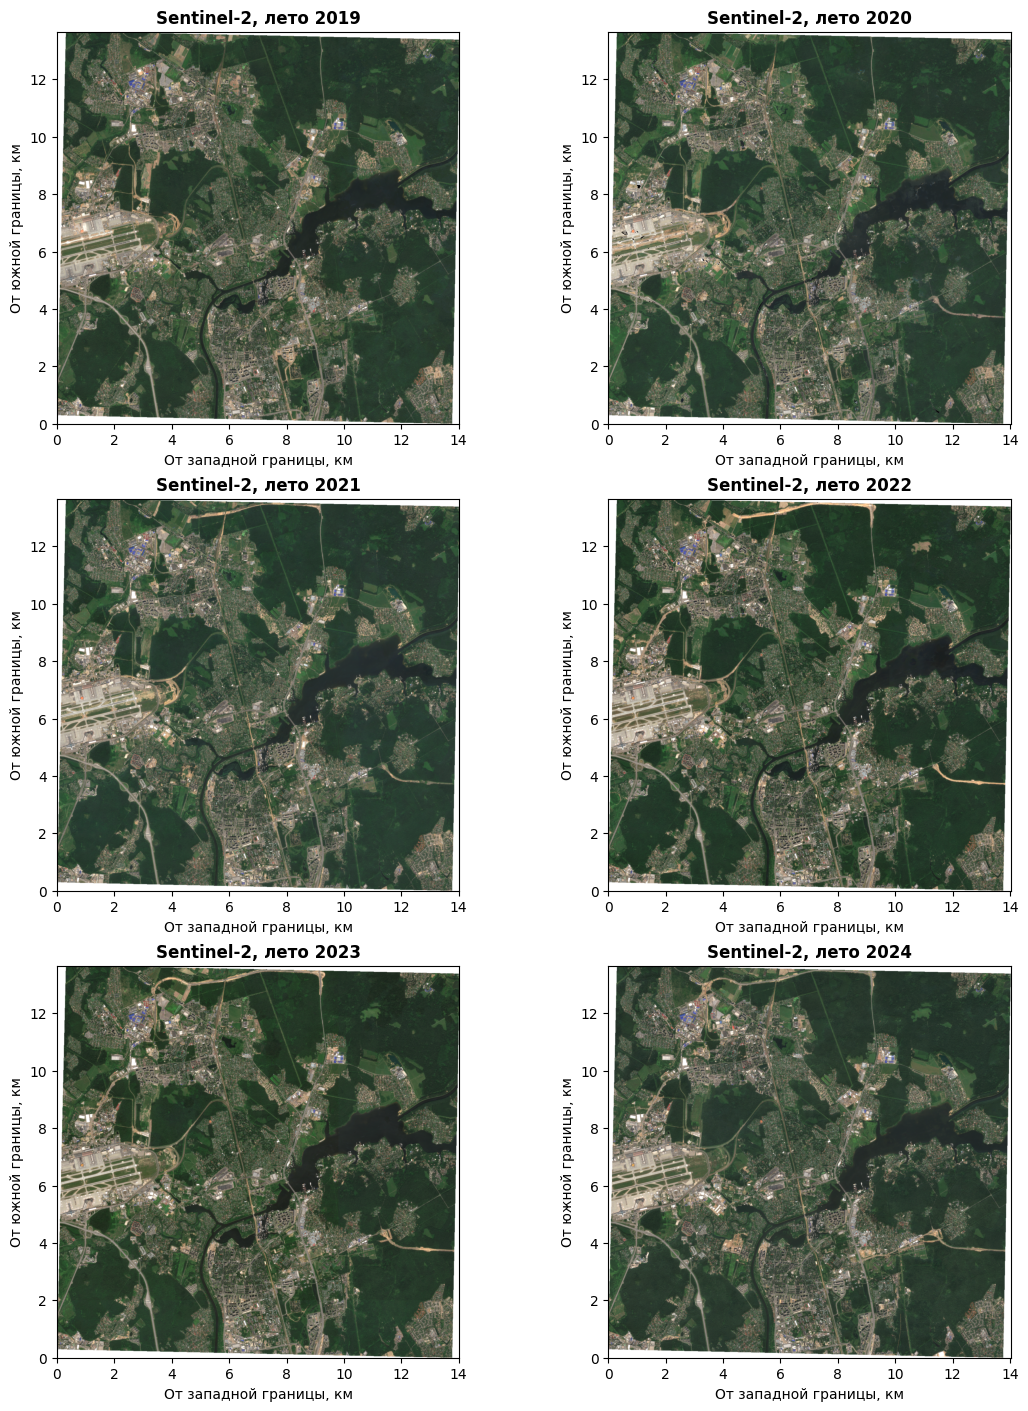

In [12]:
def check_grid(src):
    if src.crs != rasterio.crs.CRS.from_string(EXPORT_CRS):
        raise ValueError(f'Другая проекция: {src.name}')
    if src.shape != (HEIGHT, WIDTH) or not src.transform.almost_equals(GRID):
        raise ValueError(f'Растр не совпадает с общей сеткой: {src.name}')
    if not src.crs.is_projected or src.crs.linear_units != 'metre':
        raise ValueError('Для площадей нужна метрическая система координат.')


sentinel_data = {}
metadata_rows = []
for year in YEARS:
    path = DATA / f'sentinel2_summer_{year}.tif'
    if not path.is_file():
        raise FileNotFoundError(f'Отсутствует {path}. Сначала выполняется раздел 3.')
    with rasterio.open(path) as src:
        check_grid(src)
        if src.count != len(BANDS) or list(src.descriptions) != BANDS:
            raise ValueError(f'Неверный набор или порядок каналов: {path.name}')
        sentinel_data[year] = src.read(masked=True).astype('float32').filled(np.nan)
        metadata_rows.append({'Год': year, 'CRS': str(src.crs),
                              'Размер': f'{src.width} × {src.height}',
                              'Пиксель, м': f'{src.res[0]:g} × {src.res[1]:g}',
                              'Каналы': src.count, 'NoData': src.nodata})
        raster_profile = src.profile.copy()
        pixel_area_m2 = abs(src.res[0] * src.res[1])
pixel_ha = pixel_area_m2 / 10000
display(pd.DataFrame(metadata_rows).set_index('Год'))

fig, axes = plt.subplots(3, 2, figsize=(11, 14), layout='constrained')
for ax, year in zip(axes.flat, YEARS):
    rgb = np.moveaxis(sentinel_data[year][[2, 1, 0]], 0, -1)
    rgb = np.clip(np.nan_to_num(rgb) / 0.3, 0, 1) ** (1 / 1.4)
    rgb[~roi_mask] = 1
    ax.imshow(rgb, extent=extent_km)
    ax.set_title(f'Sentinel-2, лето {year}')
    ax.set_xlabel('От западной границы, км')
    ax.set_ylabel('От южной границы, км')
fig.savefig(FIGURES / 'sentinel2_rgb.png', dpi=120)
plt.show()


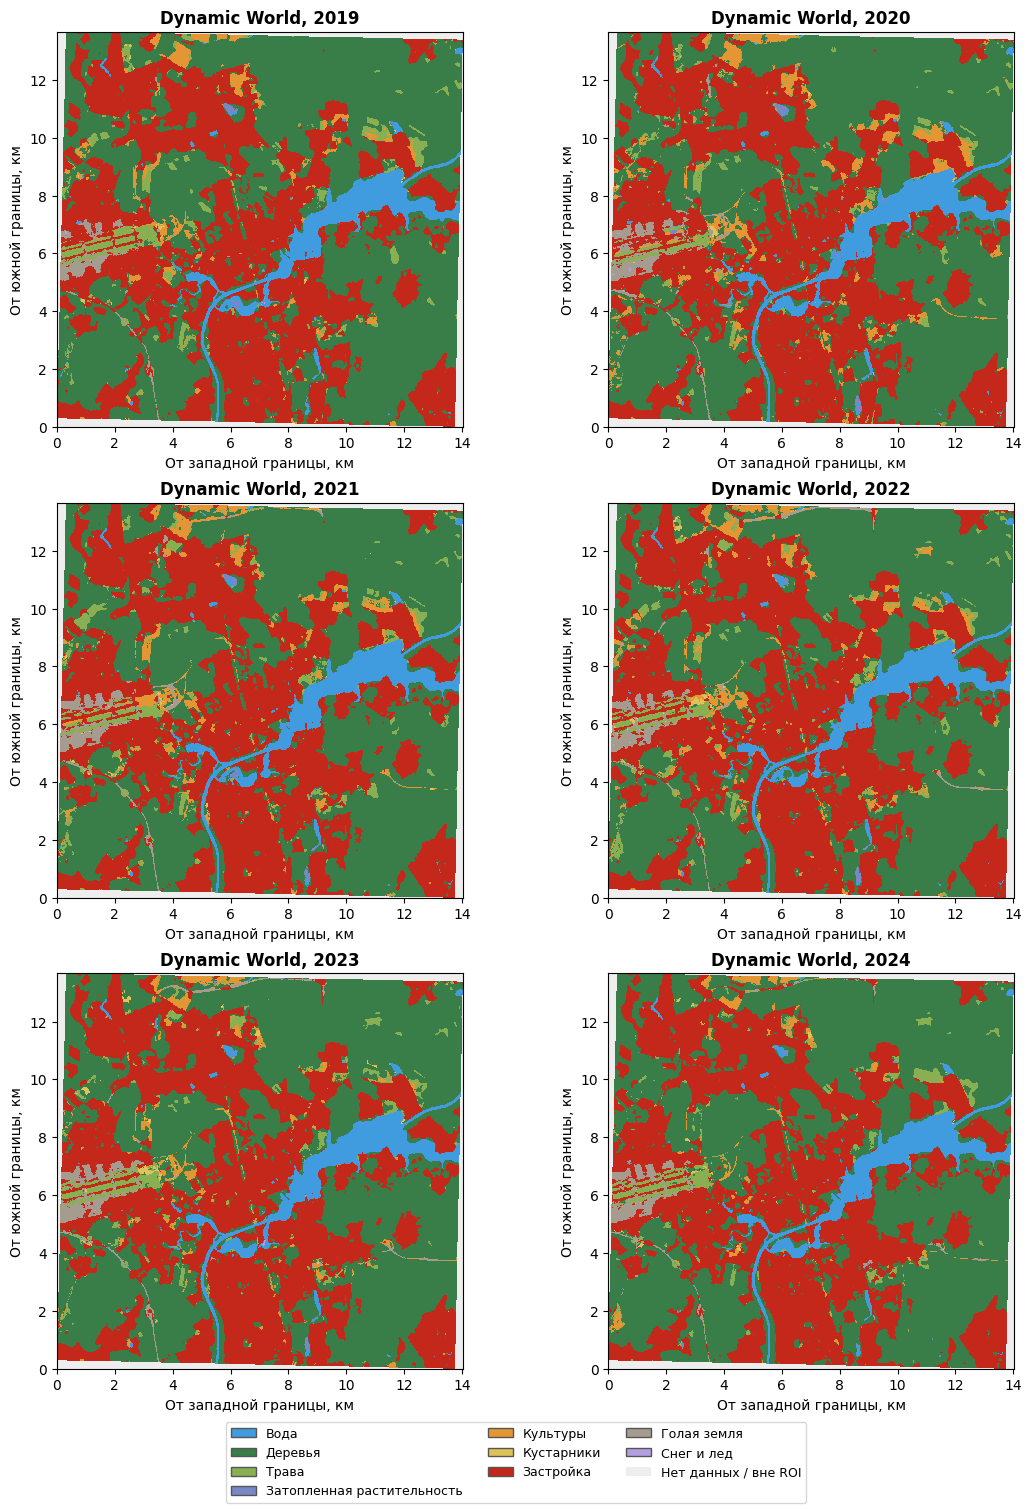

In [13]:
dw_data = {}
for year in YEARS:
    with rasterio.open(DATA / f'DYNAMICWORLD_summer_{year}.tif') as src:
        check_grid(src)
        labels = src.read(1, masked=True).astype('int16').filled(-1)
        invalid = (labels != -1) & ((labels < 0) | (labels > 8))
        if np.any(invalid):
            raise ValueError(f'Неизвестная метка Dynamic World, {year}.')
        labels[~roi_mask] = -1
        dw_data[year] = labels


def plot_class_maps(maps, names, colors, title, filename):
    cmap = ListedColormap(colors)
    cmap.set_bad('#eeeeee')
    norm = BoundaryNorm(np.arange(len(names) + 1) - 0.5, len(names))
    fig, axes = plt.subplots(3, 2, figsize=(11, 15), layout='constrained')
    for ax, year in zip(axes.flat, YEARS):
        ax.imshow(np.ma.masked_less(maps[year], 0), cmap=cmap, norm=norm,
                  interpolation='nearest', extent=extent_km)
        ax.set_title(f'{title}, {year}')
        ax.set_xlabel('От западной границы, км')
        ax.set_ylabel('От южной границы, км')
    handles = []
    for i in range(len(names)):
        handles.append(Patch(facecolor=colors[i], edgecolor='#555555', label=names[i]))
    handles.append(Patch(facecolor='#eeeeee', label='Нет данных / вне ROI'))
    fig.legend(handles=handles, loc='outside lower center', ncol=3, fontsize=9)
    fig.savefig(FIGURES / filename, dpi=120, bbox_inches='tight')
    plt.show()


plot_class_maps(dw_data, DW_NAMES, DW_COLORS, 'Dynamic World', 'dynamic_world.png')


### **4.2. Рассчитать все 8 индексов для каждого года (2019-2024)**


> **Примечание.** В качестве примера рассчета индексов можно использовать код из лекционных материалов, доступный по ссылке: https://u.to/4qBeIg





**Спектральные индексы** — это математические комбинации значений отражения в разных спектральных каналах, позволяющие выделить определенные типы объектов.








#### **Таблица 1. Основные спектральные индексы для анализа земного покрова**




| **Индекс** | **Формула** | **Назначение** | **Каналы Sentinel-2** |
|------------|-------------|----------------|------------------------|
| **NDVI** (Normalized Difference Vegetation Index) | (NIR - RED) / (NIR + RED) | Оценка состояния растительности | (B8 - B4) / (B8 + B4) |
| **NDWI** (Normalized Difference Water Index) | (GREEN - NIR) / (GREEN + NIR) | Выделение водных объектов | (B3 - B8) / (B3 + B8) |
| **NDBI** (Normalized Difference Built-up Index) | (SWIR - NIR) / (SWIR + NIR) | Выделение застроенных территорий | (B11 - B8) / (B11 + B8) |
| **SAVI** (Soil Adjusted Vegetation Index) | ((NIR - RED) / (NIR + RED + L)) * (1 + L), L=0.5 | Растительность с учетом почвы | ((B8 - B4) / (B8 + B4 + 0.5)) * 1.5 |
| **EVI** (Enhanced Vegetation Index) | 2.5 * ((NIR - RED) / (NIR + 6*RED - 7.5*BLUE + 1)) | Улучшенный вегетационный индекс | 2.5 * ((B8 - B4) / (B8 + 6*B4 - 7.5*B2 + 1)) |
| **MNDWI** (Modified NDWI) | (GREEN - SWIR) / (GREEN + SWIR) | Модифицированный водный индекс | (B3 - B11) / (B3 + B11) |
| **BSI** (Bare Soil Index) | ((SWIR + RED) - (NIR + BLUE)) / ((SWIR + RED) + (NIR + BLUE)) | Открытая почва | ((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2)) |
| **NDSI** (Normalized Difference Snow Index) | (GREEN - SWIR) / (GREEN + SWIR) | Снежный покров | (B3 - B11) / (B3 + B11) |

NDSI и MNDWI вычисляются по одной формуле, поэтому высокие значения дают и снег, и вода. Снег отличается от воды высоким отражением в ближнем ИК-канале (B8 > 0.11), а вода ИК-излучение поглощает.


#### **Таблица 2. Интерпретация значений NDVI**



| **Диапазон NDVI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| < 0.0 | Вода | Водные поверхности, снег |
| 0.0 - 0.1 | Открытая почва | Песок, камни, бетон |
| 0.1 - 0.2 | Разреженная растительность | Степи, пустыни |
| 0.2 - 0.4 | Умеренная растительность | Кустарники, луга |
| 0.4 - 0.6 | Плотная растительность | Лиственные леса |
| > 0.6 | Очень плотная растительность | Тропические леса, хвойные леса |

#### **Таблица 3. Интерпретация значений NDWI**



| **Диапазон NDWI** | **Тип объекта** | **Описание** |
|-------------------|-----------------|--------------|
| > 0.3 | Водные объекты | Реки, озера, пруды |
| 0.0 - 0.3 | Влажная почва/растительность | Болота, заливные луга |
| -0.3 - 0.0 | Сухая растительность | Обычная растительность |
| < -0.3 | Застройка/почва | Городская застройка, открытая почва |

#### **Таблица 4. Интерпретация значений NDBI**



| **Диапазон NDBI** | **Тип территории** | **Характеристика** |
|-------------------|-------------------|---------------------|
| > 0.0 | Застроенные территории | Города, промзоны |
| -0.1 - 0.0 | Смешанные территории | Пригороды, села |
| < -0.1 | Природные территории | Леса, поля, водоемы |

#### **Таблица 5. Интерпретация значений SAVI**



| **Диапазон SAVI** | **Тип покрова** | **Описание** |
|-------------------|-----------------|---------------|
| < 0.1 | Открытая почва/вода | Водные объекты, голая почва |
| 0.1 - 0.2 | Очень разреженная растительность | Пустыни, каменистые участки |
| 0.2 - 0.4 | Разреженная растительность | Степи, саванны |
| 0.4 - 0.6 | Умеренная растительность | Сельхозугодья, луга |
| > 0.6 | Плотная растительность | Леса, густые кустарники |

#### **Таблица 6. Интерпретация значений EVI**



| **Диапазон EVI** | **Состояние растительности** | **Характеристика** |
|------------------|------------------------------|---------------------|
| < 0.0 | Нет растительности | Вода, снег, облака |
| 0.0 - 0.2 | Минимальная растительность | Голая почва, урбанизированные территории |
| 0.2 - 0.3 | Низкая биомасса | Травянистая растительность |
| 0.3 - 0.5 | Средняя биомасса | Кустарники, молодые посевы |
| 0.5 - 0.8 | Высокая биомасса | Зрелые леса, интенсивное сельское хозяйство |
| > 0.8 | Очень высокая биомасса | Тропические леса |

#### **Таблица 7. Интерпретация значений MNDWI**



| **Диапазон MNDWI** | **Тип объекта** | **Характеристика** |
|--------------------|-----------------|---------------------|
| > 0.5 | Глубокая вода | Озера, моря, водохранилища |
| 0.2 - 0.5 | Мелкая вода | Реки, каналы, мелководья |
| 0.0 - 0.2 | Влажные территории | Болота, рисовые поля |
| < 0.0 | Суша | Растительность, почва, застройка |

#### **Таблица 8. Интерпретация значений BSI**



| **Диапазон BSI** | **Тип поверхности** | **Описание** |
|-------------------|-------------------|---------------|
| > 0.1 | Открытая почва | Пашни, карьеры, пустыни |
| 0.0 - 0.1 | Частично покрытая почва | Разреженная растительность |
| -0.1 - 0.0 | Смешанный покров | Переходные зоны |
| < -0.1 | Растительность/вода | Леса, водоемы, плотная растительность |

#### **Таблица 9. Интерпретация значений NDSI**



| **Диапазон NDSI** | **Тип покрова** | **Характеристика** |
|-------------------|-----------------|---------------------|
| > 0.4 | Снежный покров | Чистый снег, ледники |
| 0.2 - 0.4 | Частичный снежный покров | Смешанный снег с растительностью |
| 0.0 - 0.2 | Возможный снег/лед | Тающий снег, иней, облака |
| -0.2 - 0.0 | Переходная зона | Влажная почва, туман |
| < -0.2 | Бесснежные территории | Растительность, почва, вода |

In [14]:
def safe_divide(numerator, denominator):
    numerator = np.asarray(numerator, dtype='float32')
    denominator = np.asarray(denominator, dtype='float32')
    numerator, denominator = np.broadcast_arrays(numerator, denominator)
    valid = np.isfinite(numerator) & np.isfinite(denominator)
    valid = valid & (np.abs(denominator) > 1e-6)
    result = np.full(numerator.shape, np.nan, dtype='float32')
    np.divide(numerator, denominator, out=result, where=valid)
    return result


def calculate_indices(data):
    blue = data[0]
    green = data[1]
    red = data[2]
    nir = data[3]
    swir = data[4]

    result = {}
    result['NDVI'] = safe_divide(nir - red, nir + red)
    result['NDWI'] = safe_divide(green - nir, green + nir)
    result['NDBI'] = safe_divide(swir - nir, swir + nir)
    result['SAVI'] = 1.5 * safe_divide(nir - red, nir + red + 0.5)
    result['EVI'] = 2.5 * safe_divide(nir - red, nir + 6*red - 7.5*blue + 1)
    result['MNDWI'] = safe_divide(green - swir, green + swir)
    result['BSI'] = safe_divide(swir + red - nir - blue, swir + red + nir + blue)
    result['NDSI'] = result['MNDWI'].copy()
    return result


indices = {}
for year in YEARS:
    indices[year] = calculate_indices(sentinel_data[year])
    for name in indices[year]:
        indices[year][name][~roi_mask] = np.nan
print(f'Рассчитано {len(YEARS)} × {len(indices[2024])} = 48 индексов.')


Рассчитано 6 × 8 = 48 индексов.


### **4.3. Визуализировать каждый индекс для 2024 года с соответствующей цветовой шкалой**



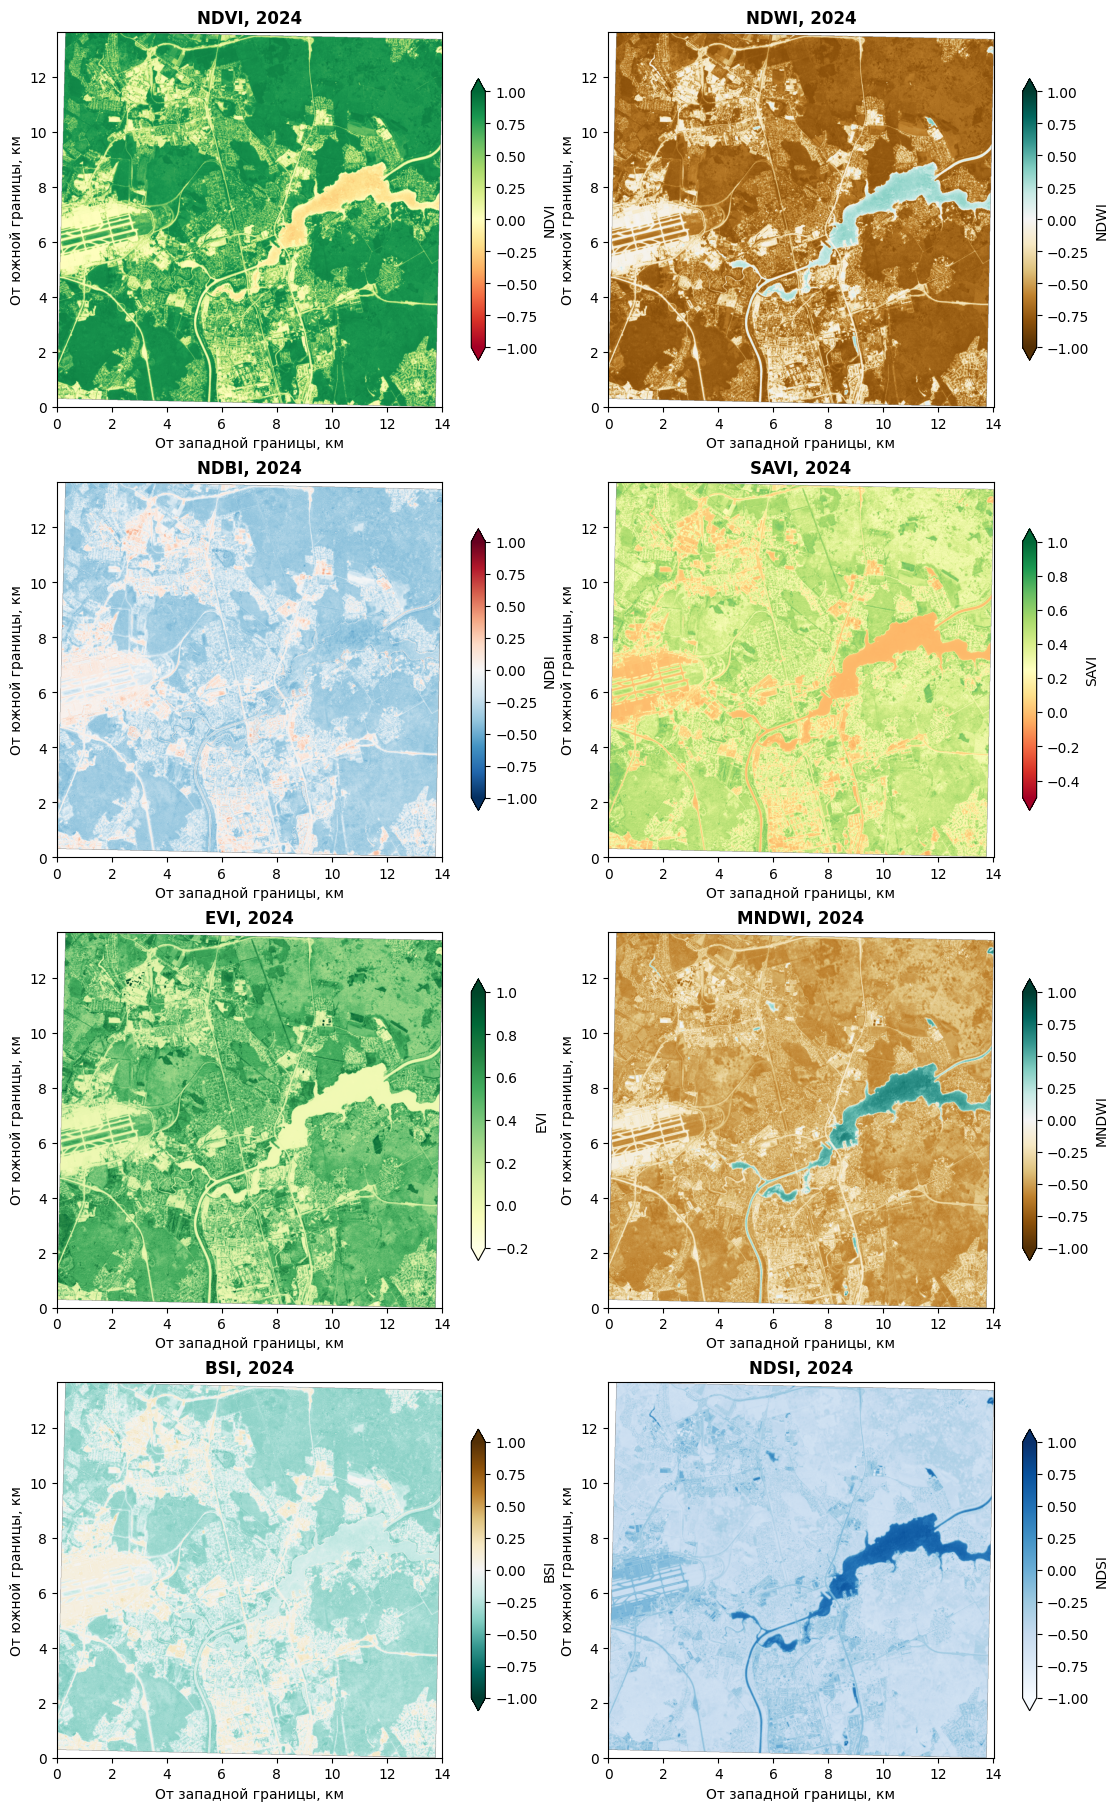

Цветовые шкалы ограничены для отображения; исходные индексы не обрезаются.


In [15]:
index_styles = {
    'NDVI': ('RdYlGn', -1, 1), 'NDWI': ('BrBG', -1, 1),
    'NDBI': ('RdBu_r', -1, 1), 'SAVI': ('RdYlGn', -0.5, 1),
    'EVI': ('YlGn', -0.2, 1), 'MNDWI': ('BrBG', -1, 1),
    'BSI': ('BrBG_r', -1, 1), 'NDSI': ('Blues', -1, 1),
}
fig, axes = plt.subplots(4, 2, figsize=(11, 18), layout='constrained')
for i, name in enumerate(index_styles):
    ax = axes.flat[i]
    cmap, vmin, vmax = index_styles[name]
    im = ax.imshow(indices[2024][name], cmap=cmap, vmin=vmin, vmax=vmax,
                   extent=extent_km)
    ax.set_title(f'{name}, 2024')
    ax.set_xlabel('От западной границы, км')
    ax.set_ylabel('От южной границы, км')
    fig.colorbar(im, ax=ax, label=name, shrink=0.75, extend='both')
fig.savefig(FIGURES / 'indices_2024.png', dpi=120)
plt.show()
print('Цветовые шкалы ограничены для отображения; исходные индексы не обрезаются.')


### **4.4. Сохранить все рассчитанные индексы в отдельные GeoTIFF файлы с сохранением геопривязки (сохранить в соответствующие папки по годам)**



In [16]:
def save_raster(filename, values, description):
    filename = Path(filename)
    filename.parent.mkdir(parents=True, exist_ok=True)
    values = np.asarray(values)
    is_float = np.issubdtype(values.dtype, np.floating)
    if is_float:
        dtype = 'float32'
        nodata = NODATA
        predictor = 3
    else:
        dtype = 'int16'
        nodata = -1
        predictor = 2
    data = np.where(np.isfinite(values), values, nodata).astype(dtype)
    profile = raster_profile.copy()
    profile.update(count=1, dtype=dtype, nodata=nodata,
                   compress='deflate', predictor=predictor)
    with rasterio.open(filename, 'w', **profile) as dst:
        dst.write(data, 1)
        dst.set_band_description(1, description)


for year in YEARS:
    for name, values in indices[year].items():
        save_raster(RESULTS / str(year) / f'{name}_{year}.tif', values, name)
print('48 GeoTIFF сохранены в 5_files/results по годам.')


48 GeoTIFF сохранены в 5_files/results по годам.


## **5. Сегментация и классификация**

**Сегментация** — процесс разделения изображения на однородные регионы (сегменты) на основе заданных критериев .


### **5.1. Многопороговая сегментация с использованием спектральных индексов**



**Задание:** Реализовать классификацию земного покрова путем замены значений пикселей в растрах индексов на метки классов согласно пороговым правилам.

**Пояснение:** По сути необходимо преобразовать непрерывные значения индексов в дискретные классы (метки) на основе пороговых значений из Таблиц 2-9. Каждому пикселю присваивается числовая метка класса (0-7) в зависимости от значений спектральных индексов.






**Алгоритм многопороговой сегментации:**
1. Создать пустой растр для меток классов (заполнить значением -1 или 255 для "неклассифицировано")
2. Последовательно применить правила классификации
3. Каждое правило проверяется только для еще не классифицированных пикселей
4. Присвоить соответствующую метку класса пикселям, удовлетворяющим условию

**Иерархия правил классификации (применять строго последовательно):**
1. **Снег/лед (метка=1)**: (NDSI > 0.4) И (B8 > 0.11)
2. **Вода (метка=0)**: ((NDWI > 0.3) ИЛИ (MNDWI > 0.2)) И (еще не классифицировано)
3. **Застройка (метка=2)**: (NDBI > 0.0) И (NDVI < 0.2) И (еще не классифицировано)
4. **Густая растительность (метка=3)**: ((NDVI > 0.6) ИЛИ (EVI > 0.5)) И (еще не классифицировано)
5. **Умеренная растительность (метка=4)**: (0.3 ≤ NDVI ≤ 0.6) И (еще не классифицировано)
6. **Разреженная растительность (метка=5)**: (0.1 ≤ NDVI < 0.3) И (еще не классифицировано)
7. **Открытая почва (метка=6)**: (BSI > 0.0) И (NDVI < 0.1) И (еще не классифицировано)
8. **Прочее (метка=7)**: все оставшиеся неклассифицированные пиксели

**Обратите внимание:** открытая почва и пашня, как и застройка, дают NDBI > 0, поэтому правило 3 относит часть открытой почвы к застройке. Учитывайте это при интерпретации результатов и сравнении с Dynamic World.


**(МОЖЕТЕ СФОРМУЛИРОВАТЬ СВОИ ПРАВИЛА, ОСНОВЫВАЯСЬ НА ТАБЛИЦАХ, ПРИВЕДЕННЫХ ВЫШЕ!)**

In [17]:
CLASS_NAMES = ['Вода', 'Снег/лед', 'Застройка', 'Густая растительность',
               'Умеренная растительность', 'Разреженная растительность',
               'Открытая почва', 'Прочее']
CLASS_COLORS = ['#419bdf', '#ffffff', '#c4281b', '#397d49',
                '#88b053', '#c6e48b', '#a59b8f', '#808080']


def segment_landcover(index, nir, roi_mask):
    valid = roi_mask & np.isfinite(nir)
    for values in index.values():
        valid &= np.isfinite(values)
    labels = np.full(nir.shape, -1, dtype='int16')
    ndvi = index['NDVI']
    # Проверяем классы по очереди. Уже найденные классы не меняем.
    condition = (index['NDSI'] > 0.4) & (nir > 0.11)
    labels[valid & condition] = 1

    condition = (index['NDWI'] > 0.3) | (index['MNDWI'] > 0.2)
    labels[valid & (labels == -1) & condition] = 0

    condition = (index['NDBI'] > 0) & (ndvi < 0.2)
    labels[valid & (labels == -1) & condition] = 2

    condition = (ndvi > 0.6) | (index['EVI'] > 0.5)
    labels[valid & (labels == -1) & condition] = 3

    condition = (ndvi >= 0.3) & (ndvi <= 0.6)
    labels[valid & (labels == -1) & condition] = 4

    condition = (ndvi >= 0.1) & (ndvi < 0.3)
    labels[valid & (labels == -1) & condition] = 5

    condition = (index['BSI'] > 0) & (ndvi < 0.1)
    labels[valid & (labels == -1) & condition] = 6
    labels[valid & (labels == -1)] = 7
    return labels


labels_2024 = segment_landcover(indices[2024], sentinel_data[2024][3], roi_mask)
print('Метки 2024 года:', np.unique(labels_2024[labels_2024 >= 0]))


Метки 2024 года: [0 1 2 3 4 5 6 7]



### **5.2. Подсчет количества пикселей каждого класса**



**Задание:** После замены значений индексов на метки классов, подсчитать количество пикселей для каждой метки класса.

**Пояснение:** Используйте функции numpy.unique() или аналогичные для подсчета количества пикселей с каждой меткой. Это позволит получить статистику распределения классов на изображении.

**Что нужно получить:**
- Массив уникальных меток классов (0-7)
- Количество пикселей для каждой метки
- Процентное соотношение классов от общего числа пикселей

In [18]:
codes, counts = np.unique(labels_2024[labels_2024 >= 0], return_counts=True)
names_2024 = []
for code in codes:
    names_2024.append(CLASS_NAMES[code])
pixel_table_2024 = pd.DataFrame({'Класс': names_2024,
                                'Пиксели': counts,
                                'Доля ROI, %': counts / roi_mask.sum() * 100})
display(pixel_table_2024.set_index('Класс').round(2))


,Пиксели,"Доля ROI, %"
Класс,,
Вода,63654,3.47
Снег/лед,20,0.00
Застройка,161687,8.82
Густая растительность,1227359,66.93
Умеренная растительность,274658,14.98
Разреженная растительность,88047,4.80
Открытая почва,11402,0.62
Прочее,6999,0.38


### **5.3. Применение сегментации ко всем временным срезам**




**Задание:** Применить разработанный алгоритм сегментации ко всем медианным композитам (2019-2024).

**Пояснение:** Использовать одинаковые пороговые значения для всех лет для обеспечения сопоставимости результатов при анализе динамики. Сохранить результаты сегментации как растры с метками классов.

**Выходные данные:**
- 6 растров с метками классов (по одному на каждый год)
- Таблица с количеством пикселей каждого класса для каждого года
- Формат сохранения: GeoTIFF с сохранением геопривязки

In [19]:
segmented = {}
for year in YEARS:
    segmented[year] = segment_landcover(indices[year], sentinel_data[year][3], roi_mask)
    save_raster(RESULTS / str(year) / f'segmentation_{year}.tif',
                segmented[year], 'landcover_class')

# Оставляем пиксели, для которых есть данные во все годы.
common_mask = roi_mask.copy()
coverage = []
for year in YEARS:
    seg_valid = segmented[year] >= 0
    dw_valid = dw_data[year] >= 0
    common_mask = common_mask & seg_valid & dw_valid
    coverage.append({'Год': year, 'Sentinel-2, % ROI': 100 * (seg_valid & roi_mask).sum() / roi_mask.sum(),
                     'Dynamic World, % ROI': 100 * (dw_valid & roi_mask).sum() / roi_mask.sum()})
if not np.any(common_mask):
    raise ValueError('Нет общей области достоверных данных для всех лет.')
common_area_ha = common_mask.sum() * pixel_ha
display(pd.DataFrame(coverage).set_index('Год').round(2))
print(f'Общая область анализа: {common_area_ha / 100:.2f} км², '
      f'{100 * common_mask.sum() / roi_mask.sum():.2f}% ROI.')


def count_pixels(maps, names, mask):
    result = {}
    for year in YEARS:
        labels = maps[year][mask]
        counts = []
        for code in range(len(names)):
            counts.append(np.count_nonzero(labels == code))
        result[year] = counts
    return pd.DataFrame(result, index=pd.Index(names, name='Класс')).astype('int64')


pixel_counts = count_pixels(segmented, CLASS_NAMES, common_mask)
display(pixel_counts)
pixel_counts.to_csv(RESULTS / 'segmentation_pixels.csv', encoding='utf-8-sig')
save_raster(RESULTS / 'common_mask.tif', np.where(roi_mask, common_mask.astype('int16'), -1),
            'common_valid_area')


,"Sentinel-2, % ROI","Dynamic World, % ROI"
Год,,
2019,100.00,100.00
2020,99.95,100.00
2021,100.00,100.00
2022,100.00,100.00
2023,100.00,100.00
2024,100.00,100.00


Общая область анализа: 183.29 км², 99.95% ROI.


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,60152,56493,61579,59011,61371,63573
Снег/лед,13,14,8,26,25,20
Застройка,150015,156065,155404,161203,156643,161199
Густая растительность,1217891,1221750,1223861,1232421,1224389,1227359
Умеренная растительность,301597,292517,289366,273260,279630,274633
Разреженная растительность,89324,89924,87817,88921,92560,87980
Открытая почва,8924,8872,9285,10876,11145,11250
Прочее,4976,7257,5572,7174,7129,6878


Площади и совпадение методов рассчитаны для одной и той же области во все годы. Проценты ROI рассчитаны от полной площади выбранного участка.


### **5.4. Визуализация результатов сегментации**






**Задание:** Создать тематические карты классификации с легендой.

**Пояснение:** Назначить каждой метке класса соответствующий цвет для визуализации. Использовать стандартную цветовую схему для классов земного покрова.

**Цветовая схема для визуализации:**
- 0 - Вода: синий (#419bdf)
- 1 - Снег/лед: белый (#ffffff)  
- 2 - Застройка: красный (#c4281b)
- 3 - Густая растительность: темно-зеленый (#397d49)
- 4 - Умеренная растительность: зеленый (#88b053)
- 5 - Разреженная растительность: светло-зеленый (#c6e48b)
- 6 - Открытая почва: коричневый (#a59b8f)
- 7 - Прочее: серый (#808080)

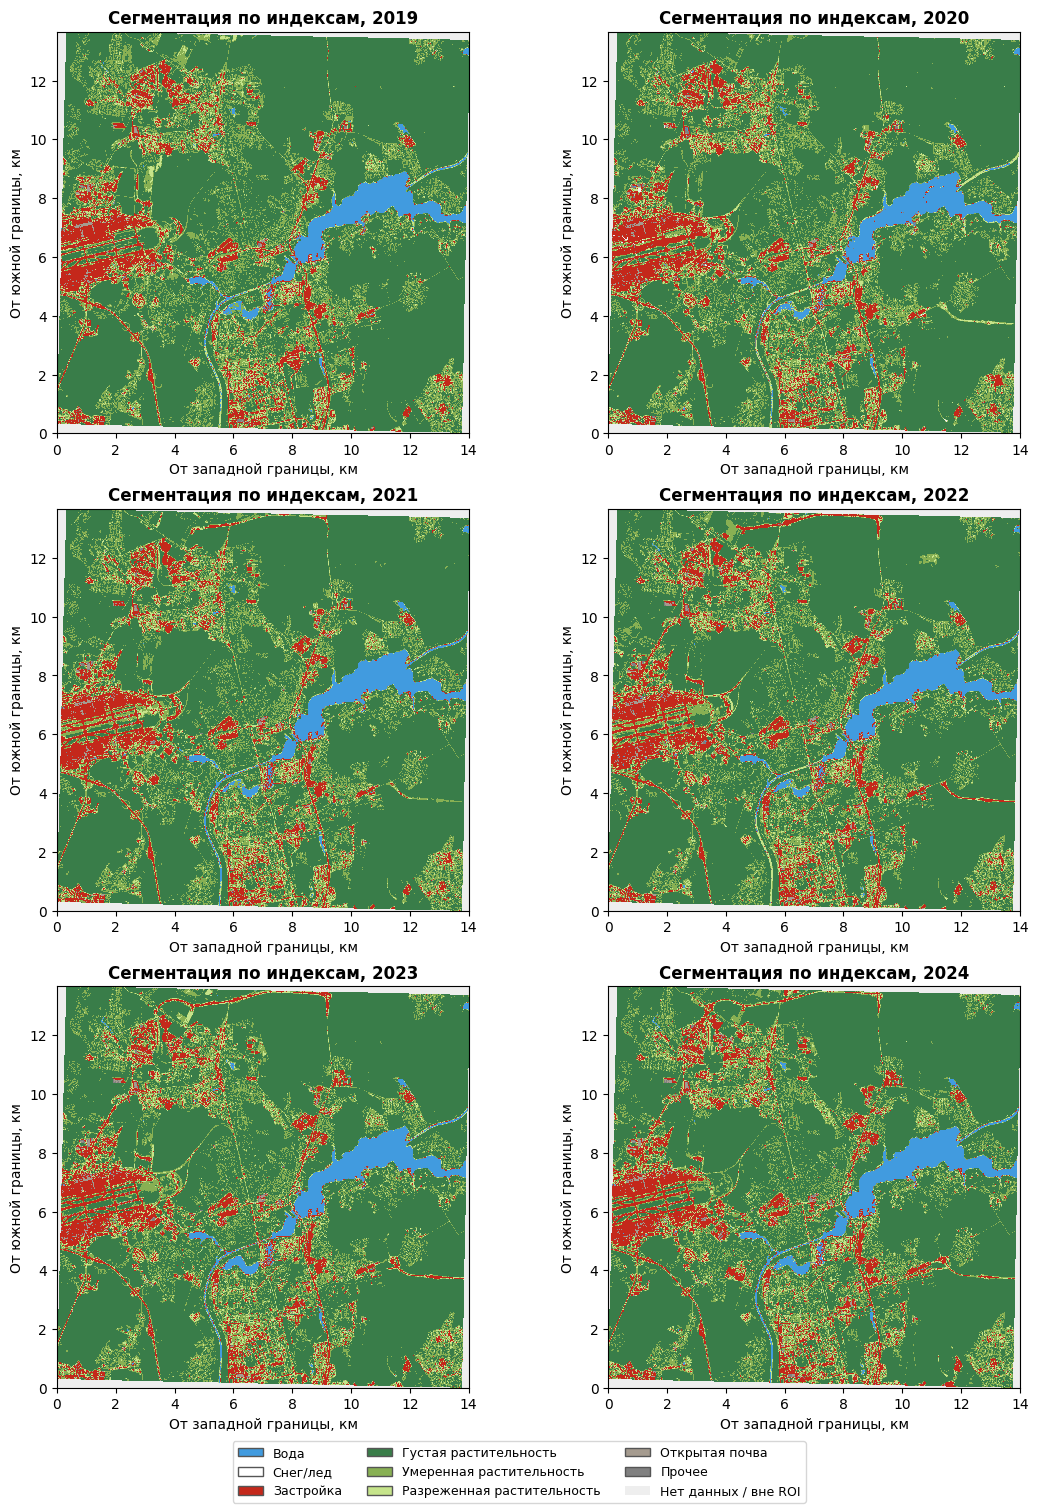

In [20]:
plot_class_maps(segmented, CLASS_NAMES, CLASS_COLORS,
                'Сегментация по индексам', 'segmentation.png')


## **6. Анализ динамики изменений на сегментированных растрах**

### **6.1. Рассчитать площади всех классов для каждого года**



**Формула перевода пикселей в площадь:**
```
Площадь (га) = Количество_пикселей × (Разрешение_м)² / 10000
Площадь (км²) = Количество_пикселей × (Разрешение_м)² / 1000000
```
Для Sentinel-2: разрешение = 10 м, следовательно:
- 1 пиксель = 100 м² = 0.01 га
- 100 пикселей = 1 га
- 10000 пикселей = 1 км²

Формула верна для растров в метрической проекции (UTM), где размер пикселя задан в метрах; размер пикселя берите из растра (`src.res`).

In [21]:
areas_ha = pixel_counts * pixel_ha
areas_km2 = areas_ha / 100
percent_roi = pixel_counts / roi_mask.sum() * 100
for title, table, filename in [
        ('Площадь, га', areas_ha, 'segmentation_area_ha.csv'),
        ('Площадь, км²', areas_km2, 'segmentation_area_km2.csv'),
        ('Доля общей площади ROI, %', percent_roi, 'segmentation_percent_roi.csv')]:
    print(title)
    display(table.round(2))
    table.to_csv(RESULTS / filename, encoding='utf-8-sig')
print('Временные ряды рассчитаны на общей маске; пропуски не считаются классом «Прочее».')


Площадь, га


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,601.52,564.93,615.79,590.11,613.71,635.73
Снег/лед,0.13,0.14,0.08,0.26,0.25,0.20
Застройка,1500.15,1560.65,1554.04,1612.03,1566.43,1611.99
Густая растительность,12178.91,12217.50,12238.61,12324.21,12243.89,12273.59
Умеренная растительность,3015.97,2925.17,2893.66,2732.60,2796.30,2746.33
Разреженная растительность,893.24,899.24,878.17,889.21,925.60,879.80
Открытая почва,89.24,88.72,92.85,108.76,111.45,112.50
Прочее,49.76,72.57,55.72,71.74,71.29,68.78


Площадь, км²


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,6.02,5.65,6.16,5.90,6.14,6.36
Снег/лед,0.00,0.00,0.00,0.00,0.00,0.00
Застройка,15.00,15.61,15.54,16.12,15.66,16.12
Густая растительность,121.79,122.18,122.39,123.24,122.44,122.74
Умеренная растительность,30.16,29.25,28.94,27.33,27.96,27.46
Разреженная растительность,8.93,8.99,8.78,8.89,9.26,8.80
Открытая почва,0.89,0.89,0.93,1.09,1.11,1.12
Прочее,0.50,0.73,0.56,0.72,0.71,0.69


Доля общей площади ROI, %


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,3.28,3.08,3.36,3.22,3.35,3.47
Снег/лед,0.00,0.00,0.00,0.00,0.00,0.00
Застройка,8.18,8.51,8.47,8.79,8.54,8.79
Густая растительность,66.41,66.62,66.74,67.20,66.77,66.93
Умеренная растительность,16.45,15.95,15.78,14.90,15.25,14.98
Разреженная растительность,4.87,4.90,4.79,4.85,5.05,4.80
Открытая почва,0.49,0.48,0.51,0.59,0.61,0.61
Прочее,0.27,0.40,0.30,0.39,0.39,0.38


Временные ряды рассчитаны на общей маске; пропуски не считаются классом «Прочее».


### **6.2. Построить графики динамики изменений для каждого класса**



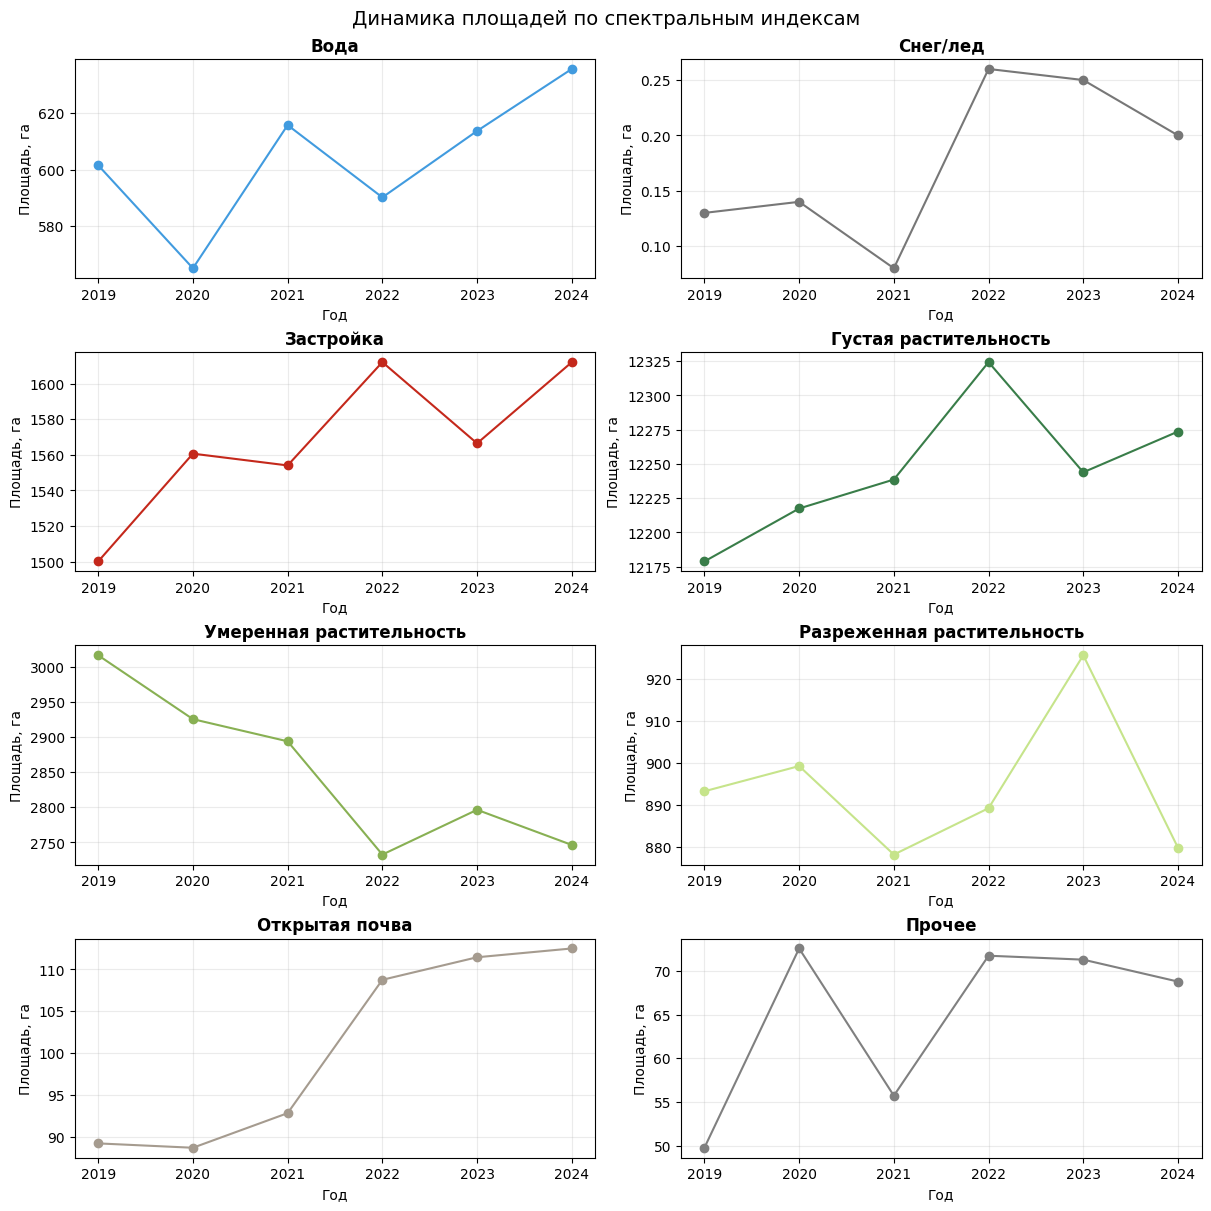

In [22]:
def plot_dynamics(areas, names, colors, title, filename, comparison=None):
    rows = int(np.ceil(len(names) / 2))
    fig, axes = plt.subplots(rows, 2, figsize=(12, rows * 3),
                             layout='constrained', squeeze=False)
    for i in range(len(names)):
        ax = axes.flat[i]
        name = names[i]
        line_color = colors[i]
        if line_color.lower() == '#ffffff':
            line_color = '#777777'
        label = None
        if comparison is not None:
            label = 'По индексам'
        ax.plot(YEARS, areas.loc[name, YEARS], 'o-', color=line_color, label=label)
        if comparison is not None:
            ax.plot(YEARS, comparison.loc[name, YEARS], 's--',
                     color='#202020', label='Dynamic World')
            ax.legend(fontsize=8)
        ax.set_title(name)
        ax.set_xlabel('Год')
        ax.set_ylabel('Площадь, га')
        ax.set_xticks(YEARS)
        ax.grid(alpha=0.25)
    for ax in list(axes.flat)[len(names):]:
        ax.axis('off')
    fig.suptitle(title, fontsize=14)
    fig.savefig(FIGURES / filename, dpi=120)
    plt.show()


plot_dynamics(areas_ha, CLASS_NAMES, CLASS_COLORS,
              'Динамика площадей по спектральным индексам', 'segmentation_dynamics.png')


### **6.3. Рассчитать все статистические показатели**



**Обязательные метрики для каждого класса:**

1. **Абсолютные показатели:**
   - Площадь в га и км² для каждого года
   - Количество пикселей
   - Процент от общей площади ROI

2. **Показатели изменений:**
   - Абсолютное изменение площади (га): ΔS = S₂₀₂₄ - S₂₀₁₉
   - Относительное изменение (%): (S₂₀₂₄ - S₂₀₁₉) / S₂₀₁₉ × 100%
   - Среднегодовой прирост (га/год): ΔS / количество_лет (2024 - 2019 = 5)
   - Среднегодовой темп роста (%/год): ((S₂₀₂₄/S₂₀₁₉)^(1/5) - 1) × 100%

3. **Статистика временного ряда:**
   - Коэффициент вариации: CV = σ/μ × 100% (вспомните материал прошлого семестра, а именно работу в numpy)
   - Стандартное отклонение площадей
   - Наклон линейного тренда площади (га/год) и коэффициент детерминации R² (`np.polyfit`)

In [23]:
def calculate_statistics(areas):
    rows = []
    x = np.array(YEARS, dtype=float) - YEARS[0]
    n_years = YEARS[-1] - YEARS[0]

    for name in areas.index:
        values = areas.loc[name, YEARS].to_numpy(dtype=float)
        first = values[0]
        last = values[-1]
        delta = last - first

        if first > 0:
            relative = delta / first * 100
            rate = ((last / first) ** (1 / n_years) - 1) * 100
        else:
            relative = np.nan
            rate = np.nan

        mean = np.mean(values)
        std = np.std(values, ddof=0)
        if mean > 0:
            cv = std / mean * 100
        else:
            cv = np.nan

        slope, intercept = np.polyfit(x, values, 1)
        prediction = slope * x + intercept
        total = np.sum((values - mean) ** 2)
        error = np.sum((values - prediction) ** 2)
        if total > 1e-12:
            r2 = 1 - error / total
        else:
            r2 = 0.0
        r2 = float(np.clip(r2, 0, 1))
        if np.ptp(values) < 1e-10:
            slope = 0.0

        rows.append({
            'S_2019, га': first, 'S_2024, га': last,
            'ΔS, га': delta, 'Δ, %': relative,
            'Прирост, га/год': delta / n_years,
            'Темп, %/год': rate, 'Среднее, га': mean,
            'σ, га': std, 'CV, %': cv,
            'Наклон, га/год': slope, 'R²': r2,
        })

    stats = pd.DataFrame(rows, index=areas.index)
    stats['Значимое изменение'] = ((stats['Δ, %'].abs() > 10) &
                                  (stats['ΔS, га'].abs() > 10) &
                                  (stats['R²'] >= 0.5))
    return stats


statistics = calculate_statistics(areas_ha)
display(statistics.round(2))
statistics.to_csv(RESULTS / 'segmentation_statistics.csv', encoding='utf-8-sig')
print('σ рассчитано по всем шести годам (ddof=0). При нулевой начальной площади Δ% и темп не определены.')


,"S_2019, га","S_2024, га","ΔS, га","Δ, %","Прирост, га/год","Темп, %/год","Среднее, га","σ, га","CV, %","Наклон, га/год",R²,Значимое изменение
Класс,,,,,,,,,,,,
Вода,601.52,635.73,34.21,5.69,6.84,1.11,603.63,22.23,3.68,8.33,0.41,False
Снег/лед,0.13,0.20,0.07,53.85,0.01,9.00,0.18,0.07,37.07,0.02,0.41,False
Застройка,1500.15,1611.99,111.84,7.46,22.37,1.45,1567.55,38.14,2.43,18.13,0.66,False
Густая растительность,12178.91,12273.59,94.68,0.78,18.94,0.16,12246.12,45.19,0.37,18.23,0.47,False
Умеренная растительность,3015.97,2746.33,-269.64,-8.94,-53.93,-1.86,2851.67,102.06,3.58,-54.17,0.82,False
Разреженная растительность,893.24,879.80,-13.44,-1.50,-2.69,-0.30,894.21,15.82,1.77,0.65,0.00,False
Открытая почва,89.24,112.50,23.26,26.06,4.65,4.74,100.59,10.46,10.40,5.73,0.87,True
Прочее,49.76,68.78,19.02,38.22,3.80,6.69,64.98,8.90,13.69,3.07,0.35,False


σ рассчитано по всем шести годам (ddof=0). При нулевой начальной площади Δ% и темп не определены.


### **6.4. Определить какие классы показали наибольшие изменения**



**Критерии определения значимых изменений:**
- Изменение площади > 10% от начального значения
- Абсолютное изменение > 10 га
- Изменение направленное: R² линейного тренда ≥ 0.5 (иначе это межгодовые колебания)
- Ранжировать классы по величине относительных изменений

In [24]:
def ranked_changes(stats):
    ranking = stats.copy()
    ranking['_rank'] = ranking['Δ, %'].abs()
    ranking = ranking.sort_values('_rank', ascending=False)
    significant = ranking[ranking['Значимое изменение']]
    columns = ['S_2019, га', 'S_2024, га', 'ΔS, га', 'Δ, %', 'R²']
    print('Ранжирование по модулю относительного изменения:')
    display(ranking[columns].round(2))
    print('Направленные изменения по трём критериям задания:')
    if significant.empty:
        print('Классов, одновременно отвечающих всем трём критериям, нет.')
    else:
        display(significant[columns].round(2))
    new_classes = stats[(stats['S_2019, га'] == 0) & (stats['S_2024, га'] > 0)]
    if not new_classes.empty:
        print('Появились при нулевой начальной площади:', ', '.join(new_classes.index),
              '(относительное изменение не определено).')
    return significant


significant_seg = ranked_changes(statistics)


Ранжирование по модулю относительного изменения:


,"S_2019, га","S_2024, га","ΔS, га","Δ, %",R²
Класс,,,,,
Снег/лед,0.13,0.20,0.07,53.85,0.41
Прочее,49.76,68.78,19.02,38.22,0.35
Открытая почва,89.24,112.50,23.26,26.06,0.87
Умеренная растительность,3015.97,2746.33,-269.64,-8.94,0.82
Застройка,1500.15,1611.99,111.84,7.46,0.66
Вода,601.52,635.73,34.21,5.69,0.41
Разреженная растительность,893.24,879.80,-13.44,-1.50,0.00
Густая растительность,12178.91,12273.59,94.68,0.78,0.47


Направленные изменения по трём критериям задания:


,"S_2019, га","S_2024, га","ΔS, га","Δ, %",R²
Класс,,,,,
Открытая почва,89.24,112.50,23.26,26.06,0.87


### **6.5. Создать сводную таблицу результатов**



| Класс | S_2019 (га) | S_2024 (га) | ΔS (га) | Δ% | Темп (%/год) | Тренд | CV (%) | R² |
|-------|-------------|-------------|---------|-----|--------------|-------|-----|-----|
| Вода | ... | ... | ... | ... | ... | ↑/↓/→ | ... | ... |
| Растительность | ... | ... | ... | ... | ... | ↑/↓/→ | ... | ... |
| ... | ... | ... | ... | ... | ... | ... | ... | ... |

In [25]:
def trend_name(row):
    if row['Среднее, га'] == 0:
        return 'нет класса'
    if row['Значимое изменение']:
        if row['Наклон, га/год'] > 0:
            return '↑'
        return '↓'
    if row['CV, %'] > 10:
        return 'колебания'
    return '→'


def summary_table(stats):
    table = stats[['S_2019, га', 'S_2024, га', 'ΔS, га', 'Δ, %', 'Темп, %/год',
                   'CV, %', 'R²']].copy()
    trends = []
    for name in stats.index:
        trends.append(trend_name(stats.loc[name]))
    table.insert(5, 'Тренд', trends)
    return table


summary_seg = summary_table(statistics)
display(summary_seg.round(2))
summary_seg.to_csv(RESULTS / 'segmentation_summary.csv', encoding='utf-8-sig')
print('↑/↓ — направленное изменение по критериям задания; → — малые колебания; «колебания» — без устойчивого тренда.')


,"S_2019, га","S_2024, га","ΔS, га","Δ, %","Темп, %/год",Тренд,"CV, %",R²
Класс,,,,,,,,
Вода,601.52,635.73,34.21,5.69,1.11,→,3.68,0.41
Снег/лед,0.13,0.20,0.07,53.85,9.00,колебания,37.07,0.41
Застройка,1500.15,1611.99,111.84,7.46,1.45,→,2.43,0.66
Густая растительность,12178.91,12273.59,94.68,0.78,0.16,→,0.37,0.47
Умеренная растительность,3015.97,2746.33,-269.64,-8.94,-1.86,→,3.58,0.82
Разреженная растительность,893.24,879.80,-13.44,-1.50,-0.30,→,1.77,0.00
Открытая почва,89.24,112.50,23.26,26.06,4.74,↑,10.40,0.87
Прочее,49.76,68.78,19.02,38.22,6.69,колебания,13.69,0.35


↑/↓ — направленное изменение по критериям задания; → — малые колебания; «колебания» — без устойчивого тренда.


### **6.6. Карта изменений и матрица переходов**

**Задание:** Постройте карту пикселей, сменивших класс с 2019 по 2024 год, и матрицу переходов — площадь (га), перешедшую из каждого класса в каждый. Определите, где сосредоточены основные изменения и какие переходы преобладают.

,Вода,Снег/лед,Застройка,Густая растительность,Умеренная растительность,Разреженная растительность,Открытая почва,Прочее
2019 → 2024,,,,,,,,
Вода,584.11,0.09,3.91,0.50,3.98,4.35,0.35,4.23
Снег/лед,0.09,0.03,0.00,0.00,0.00,0.00,0.01,0.00
Застройка,6.78,0.02,1120.34,24.48,98.34,185.24,47.85,17.10
Густая растительность,0.94,0.00,147.04,11240.20,656.11,123.02,7.37,4.23
Умеренная растительность,10.14,0.01,121.45,949.04,1682.97,244.02,4.89,3.45
Разреженная растительность,24.29,0.01,177.50,59.19,303.11,310.39,9.55,9.20
Открытая почва,0.53,0.00,34.01,0.13,1.22,8.22,35.42,9.71
Прочее,8.85,0.04,7.74,0.05,0.60,4.56,7.06,20.86


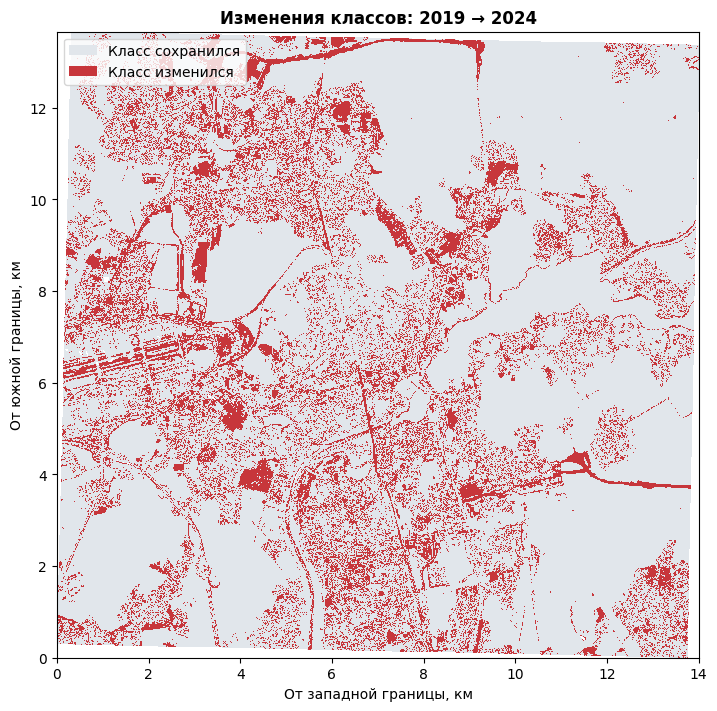

Основные переходы:


,Из класса,В класс,"Площадь, га"
0,Умеренная растительность,Густая растительность,949.04
1,Густая растительность,Умеренная растительность,656.11
2,Разреженная растительность,Умеренная растительность,303.11
3,Умеренная растительность,Разреженная растительность,244.02
4,Застройка,Разреженная растительность,185.24


,"Изменилось, га","Доля изменений, %"
Часть ROI,,
Северо-запад,1064.18,23.25
Северо-восток,495.53,10.81
Юго-запад,998.42,21.83
Юго-восток,776.47,16.90


Класс изменился на 3334.60 га (18.19% общей области анализа).


In [26]:
def transition_matrix(first, last, mask, names):
    size = len(names)
    matrix = np.zeros((size, size), dtype=float)
    for i in range(size):
        from_class = mask & (first == i)
        for j in range(size):
            count = np.count_nonzero(from_class & (last == j))
            matrix[i, j] = count * pixel_ha
    return pd.DataFrame(matrix, index=names, columns=names)


transitions = transition_matrix(segmented[2019], segmented[2024], common_mask, CLASS_NAMES)
transitions.index.name = '2019 → 2024'
display(transitions.round(2))
transitions.to_csv(RESULTS / 'transitions_2019_2024_ha.csv', encoding='utf-8-sig')
changed = common_mask & (segmented[2019] != segmented[2024])
change_map = np.full(common_mask.shape, -1, dtype='int16')
change_map[common_mask] = changed[common_mask].astype('int16')
save_raster(RESULTS / 'changes_2019_2024.tif', change_map, 'changed_class')

fig, ax = plt.subplots(figsize=(8, 7), layout='constrained')
change_cmap = ListedColormap(['#e1e6eb', '#c7363b'])
change_cmap.set_bad('#ffffff')
ax.imshow(np.ma.masked_less(change_map, 0), cmap=change_cmap, vmin=0, vmax=1,
           interpolation='nearest', extent=extent_km)
ax.set_title('Изменения классов: 2019 → 2024')
ax.set_xlabel('От западной границы, км')
ax.set_ylabel('От южной границы, км')
ax.legend(handles=[Patch(facecolor='#e1e6eb', label='Класс сохранился'),
                    Patch(facecolor='#c7363b', label='Класс изменился')], loc='upper left')
fig.savefig(FIGURES / 'changes_2019_2024.png', dpi=120)
plt.show()

transition_rows = []
for i, source in enumerate(CLASS_NAMES):
    for j, target in enumerate(CLASS_NAMES):
        if i != j and transitions.iloc[i, j] > 0:
            transition_rows.append({'Из класса': source, 'В класс': target,
                                    'Площадь, га': transitions.iloc[i, j]})
top_transitions = pd.DataFrame(transition_rows, columns=['Из класса', 'В класс', 'Площадь, га'])
top_transitions = top_transitions.sort_values('Площадь, га', ascending=False).reset_index(drop=True)
print('Основные переходы:')
display(top_transitions.head(5).round(2))

# Строки растра идут с севера на юг.
quadrants = {'Северо-запад': (slice(0, HEIGHT//2), slice(0, WIDTH//2)),
             'Северо-восток': (slice(0, HEIGHT//2), slice(WIDTH//2, WIDTH)),
             'Юго-запад': (slice(HEIGHT//2, HEIGHT), slice(0, WIDTH//2)),
             'Юго-восток': (slice(HEIGHT//2, HEIGHT), slice(WIDTH//2, WIDTH))}
spatial_rows = []
for name, window in quadrants.items():
    valid_count = common_mask[window].sum()
    count = changed[window].sum()
    if valid_count > 0:
        percent = 100 * count / valid_count
    else:
        percent = np.nan
    spatial_rows.append({'Часть ROI': name, 'Изменилось, га': count * pixel_ha,
                         'Доля изменений, %': percent})
spatial_changes = pd.DataFrame(spatial_rows).set_index('Часть ROI')
display(spatial_changes.round(2))
changed_area_ha = changed.sum() * pixel_ha
print(f'Класс изменился на {changed_area_ha:.2f} га '
      f'({100*changed.sum()/common_mask.sum():.2f}% общей области анализа).')


## **7. Сравнение с картами Dynamic World**

### **7.1. Рассчитать площади всех классов для каждого года по картам классификации**



In [27]:
dw_pixels = count_pixels(dw_data, DW_NAMES, common_mask)
dw_areas_ha = dw_pixels * pixel_ha
dw_areas_km2 = dw_areas_ha / 100
dw_percent_roi = dw_pixels / roi_mask.sum() * 100
for title, table, filename in [
        ('Dynamic World: количество пикселей', dw_pixels, 'dynamic_world_pixels.csv'),
        ('Dynamic World: площадь, га', dw_areas_ha, 'dynamic_world_area_ha.csv'),
        ('Dynamic World: площадь, км²', dw_areas_km2, 'dynamic_world_area_km2.csv'),
        ('Dynamic World: доля ROI, %', dw_percent_roi, 'dynamic_world_percent_roi.csv')]:
    print(title)
    display(table.round(2))
    table.to_csv(RESULTS / filename, encoding='utf-8-sig')


Dynamic World: количество пикселей


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,86398,89762,87211,86355,87548,86771
Деревья,928634,892598,886127,872353,901003,927489
Трава,53859,38434,50335,53123,43706,41269
Затопленная растительность,1752,3613,2523,1689,1178,579
Культуры,37912,66423,48844,49109,32887,21663
Кустарники,1436,1317,1726,2919,4613,1811
Застройка,707356,716767,732086,743315,734691,731522
Голая земля,15408,23806,23986,23947,27060,21786
Снег и лед,137,172,54,82,206,2


Dynamic World: площадь, га


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,863.98,897.62,872.11,863.55,875.48,867.71
Деревья,9286.34,8925.98,8861.27,8723.53,9010.03,9274.89
Трава,538.59,384.34,503.35,531.23,437.06,412.69
Затопленная растительность,17.52,36.13,25.23,16.89,11.78,5.79
Культуры,379.12,664.23,488.44,491.09,328.87,216.63
Кустарники,14.36,13.17,17.26,29.19,46.13,18.11
Застройка,7073.56,7167.67,7320.86,7433.15,7346.91,7315.22
Голая земля,154.08,238.06,239.86,239.47,270.60,217.86
Снег и лед,1.37,1.72,0.54,0.82,2.06,0.02


Dynamic World: площадь, км²


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,8.64,8.98,8.72,8.64,8.75,8.68
Деревья,92.86,89.26,88.61,87.24,90.10,92.75
Трава,5.39,3.84,5.03,5.31,4.37,4.13
Затопленная растительность,0.18,0.36,0.25,0.17,0.12,0.06
Культуры,3.79,6.64,4.88,4.91,3.29,2.17
Кустарники,0.14,0.13,0.17,0.29,0.46,0.18
Застройка,70.74,71.68,73.21,74.33,73.47,73.15
Голая земля,1.54,2.38,2.40,2.39,2.71,2.18
Снег и лед,0.01,0.02,0.01,0.01,0.02,0.00


Dynamic World: доля ROI, %


,2019,2020,2021,2022,2023,2024
Класс,,,,,,
Вода,4.71,4.89,4.76,4.71,4.77,4.73
Деревья,50.64,48.67,48.32,47.57,49.13,50.58
Трава,2.94,2.10,2.74,2.90,2.38,2.25
Затопленная растительность,0.10,0.20,0.14,0.09,0.06,0.03
Культуры,2.07,3.62,2.66,2.68,1.79,1.18
Кустарники,0.08,0.07,0.09,0.16,0.25,0.10
Застройка,38.57,39.09,39.92,40.53,40.06,39.89
Голая земля,0.84,1.30,1.31,1.31,1.48,1.19
Снег и лед,0.01,0.01,0.00,0.00,0.01,0.00


### **7.2. Построить графики динамики изменений для каждого класса по картам классификации**



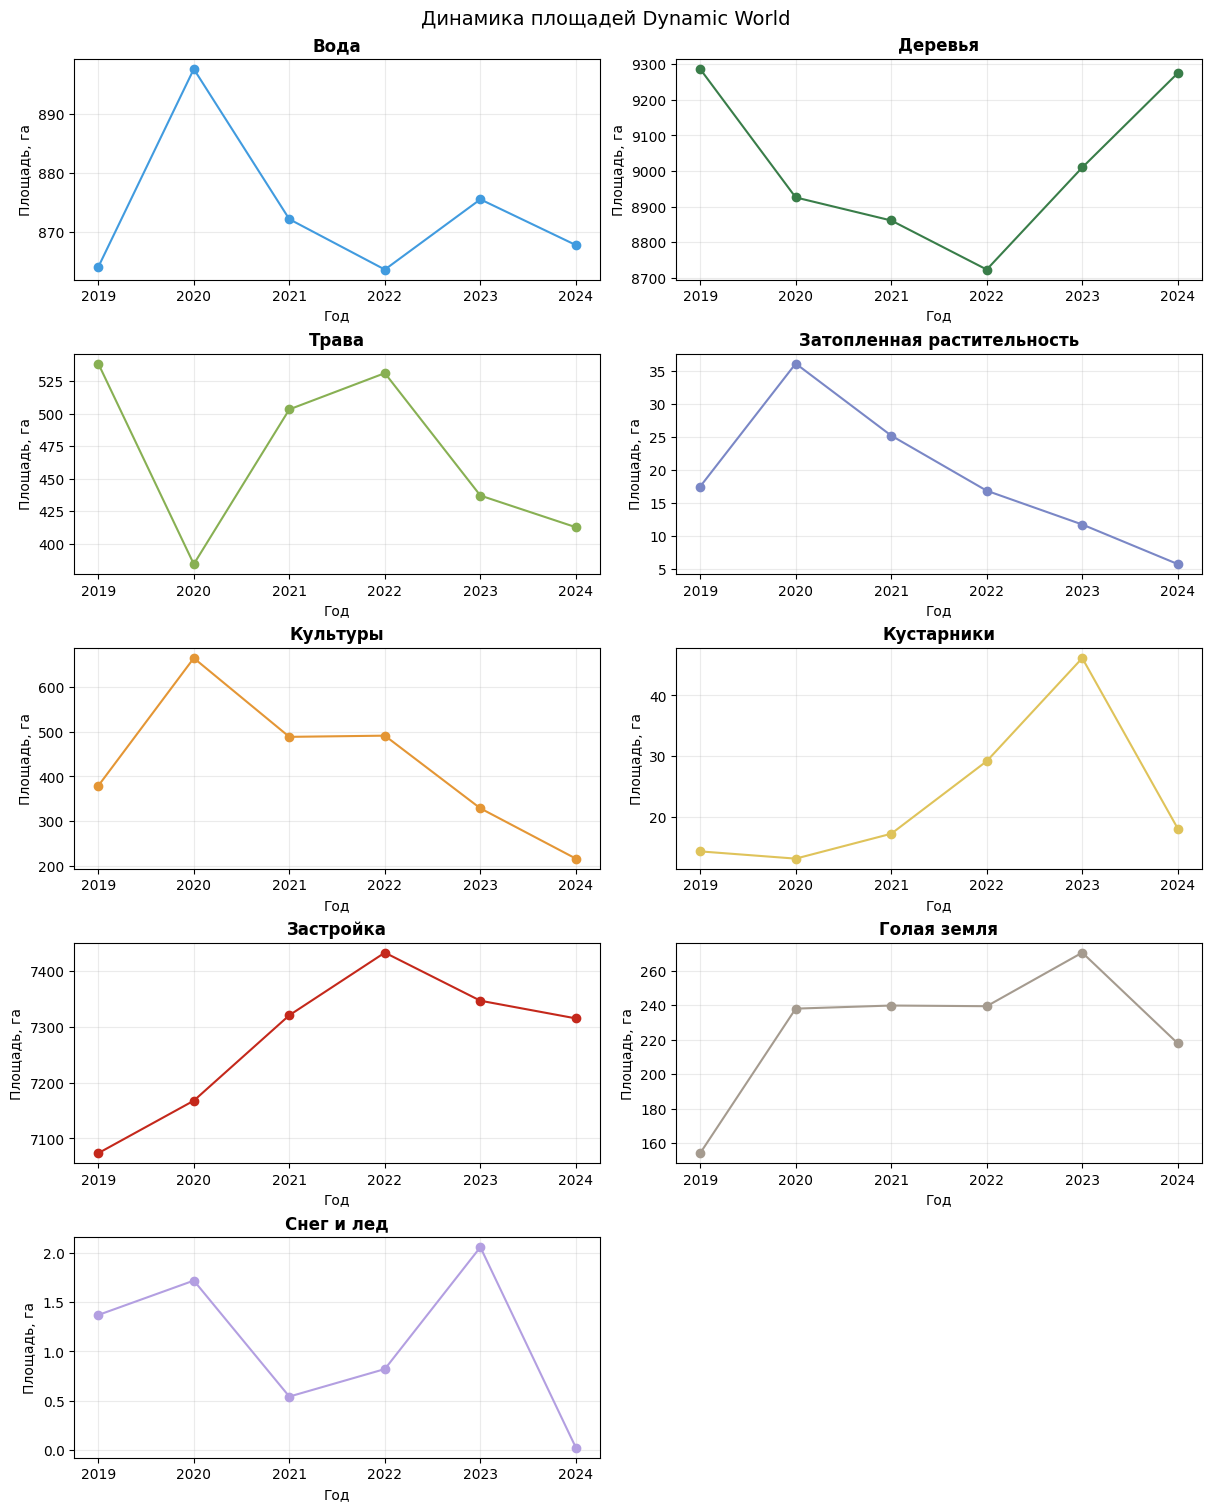

In [28]:
plot_dynamics(dw_areas_ha, DW_NAMES, DW_COLORS,
              'Динамика площадей Dynamic World', 'dynamic_world_dynamics.png')


### **7.3. Рассчитать все статистические показатели по картам классификации**



In [29]:
dw_statistics = calculate_statistics(dw_areas_ha)
display(dw_statistics.round(2))
dw_statistics.to_csv(RESULTS / 'dynamic_world_statistics.csv', encoding='utf-8-sig')


,"S_2019, га","S_2024, га","ΔS, га","Δ, %","Прирост, га/год","Темп, %/год","Среднее, га","σ, га","CV, %","Наклон, га/год",R²,Значимое изменение
Класс,,,,,,,,,,,,
Вода,863.98,867.71,3.73,0.43,0.75,0.09,873.41,11.62,1.33,-1.61,0.06,False
Деревья,9286.34,9274.89,-11.45,-0.12,-2.29,-0.02,9013.67,207.24,2.30,1.63,0.00,False
Трава,538.59,412.69,-125.90,-23.38,-25.18,-5.19,467.88,59.51,12.72,-12.67,0.13,False
Затопленная растительность,17.52,5.79,-11.73,-66.95,-2.35,-19.86,18.89,9.71,51.39,-4.00,0.50,False
Культуры,379.12,216.63,-162.49,-42.86,-32.50,-10.59,428.06,141.62,33.08,-51.88,0.39,False
Кустарники,14.36,18.11,3.75,26.11,0.75,4.75,23.04,11.56,50.17,3.70,0.30,False
Застройка,7073.56,7315.22,241.66,3.42,48.33,0.67,7276.23,119.72,1.65,53.09,0.57,False
Голая земля,154.08,217.86,63.78,41.39,12.76,7.17,226.66,35.93,15.85,11.89,0.32,False
Снег и лед,1.37,0.02,-1.35,-98.54,-0.27,-57.06,1.09,0.70,64.28,-0.16,0.14,False


### **7.4. Определить какие классы показали наибольшие изменения по картам классификации**



In [30]:
significant_dw = ranked_changes(dw_statistics)


Ранжирование по модулю относительного изменения:


,"S_2019, га","S_2024, га","ΔS, га","Δ, %",R²
Класс,,,,,
Снег и лед,1.37,0.02,-1.35,-98.54,0.14
Затопленная растительность,17.52,5.79,-11.73,-66.95,0.50
Культуры,379.12,216.63,-162.49,-42.86,0.39
Голая земля,154.08,217.86,63.78,41.39,0.32
Кустарники,14.36,18.11,3.75,26.11,0.30
Трава,538.59,412.69,-125.90,-23.38,0.13
Застройка,7073.56,7315.22,241.66,3.42,0.57
Вода,863.98,867.71,3.73,0.43,0.06
Деревья,9286.34,9274.89,-11.45,-0.12,0.00


Направленные изменения по трём критериям задания:
Классов, одновременно отвечающих всем трём критериям, нет.


### **7.5. Создать сводную таблицу результатов по картам классификации**



In [31]:
summary_dw = summary_table(dw_statistics)
display(summary_dw.round(2))
summary_dw.to_csv(RESULTS / 'dynamic_world_summary.csv', encoding='utf-8-sig')


,"S_2019, га","S_2024, га","ΔS, га","Δ, %","Темп, %/год",Тренд,"CV, %",R²
Класс,,,,,,,,
Вода,863.98,867.71,3.73,0.43,0.09,→,1.33,0.06
Деревья,9286.34,9274.89,-11.45,-0.12,-0.02,→,2.30,0.00
Трава,538.59,412.69,-125.90,-23.38,-5.19,колебания,12.72,0.13
Затопленная растительность,17.52,5.79,-11.73,-66.95,-19.86,колебания,51.39,0.50
Культуры,379.12,216.63,-162.49,-42.86,-10.59,колебания,33.08,0.39
Кустарники,14.36,18.11,3.75,26.11,4.75,колебания,50.17,0.30
Застройка,7073.56,7315.22,241.66,3.42,0.67,→,1.65,0.57
Голая земля,154.08,217.86,63.78,41.39,7.17,колебания,15.85,0.32
Снег и лед,1.37,0.02,-1.35,-98.54,-57.06,колебания,64.28,0.14


## **8. Сравнение результатов полученных по результатам сегментации и картам классификаций**

**Задание:** Сведите классы обоих методов к укрупнённым классам по таблице 10. Сравните площади укрупнённых классов по годам, рассчитайте долю совпадающих пикселей для каждого года и матрицу совпадений для 2024 года.

#### **Таблица 10. Соответствие классов сегментации и Dynamic World**

| **Укрупнённый класс** | **Метки сегментации** | **Классы Dynamic World** |
|---|---|---|
| Вода | 0 | 0 — Вода |
| Снег/лед | 1 | 8 — Снег и лед |
| Застройка | 2 | 6 — Застройка |
| Растительность | 3, 4, 5 | 1 — Деревья, 2 — Трава, 3 — Затопл. растительность, 4 — Культуры, 5 — Кустарники |
| Открытая почва | 6 | 7 — Голая земля |
| Прочее | 7 | — |

По индексам, га  Dynamic World, га  Разница, га
Год  Класс                                                          
2019 Вода                     601.52             863.98      -262.46
     Снег/лед                   0.13               1.37        -1.24
     Застройка               1500.15            7073.56     -5573.41
     Растительность         16088.12           10235.93      5852.19
     Открытая почва            89.24             154.08       -64.84
     Прочее                    49.76               0.00        49.76
2020 Вода                     564.93             897.62      -332.69
     Снег/лед                   0.14               1.72        -1.58
     Застройка               1560.65            7167.67     -5607.02
     Растительность         16041.91           10023.85      6018.06
     Открытая почва            88.72             238.06      -149.34
     Прочее                    72.57               0.00        72.57
2021 Вода                     615.79             872.11      -256.32
     Снег/лед                   0.08               0.54        -0.46
     Застройка               1554.04            7320.86     -5766.82
     Растительность         16010.44            9895.55      6114.89
     Открытая почва            92.85             239.86      -147.01
     Прочее                    55.72               0.00        55.72
2022 Вода                     590.11             863.55      -273.44
     Снег/лед                   0.26               0.82        -0.56
     Застройка               1612.03            7433.15     -5821.12
     Растительность         15946.02            9791.93      6154.09
     Открытая почва           108.76             239.47      -130.71
     Прочее                    71.74               0.00        71.74
2023 Вода                     613.71             875.48      -261.77
     Снег/лед                   0.25               2.06        -1.81
     Застройка               1566.43            7346.91     -5780.48
     Растительность         15965.79            9833.87      6131.92
     Открытая почва           111.45             270.60      -159.15
     Прочее                    71.29               0.00        71.29
2024 Вода                     635.73             867.71      -231.98
     Снег/лед                   0.20               0.02         0.18
     Застройка               1611.99            7315.22     -5703.23
     Растительность         15899.72            9928.11      5971.61
     Открытая почва           112.50             217.86      -105.36
     Прочее                    68.78               0.00        68.78

,Пиксели сравнения,"Совпадение, %"
Год,,
2019,1832892,65.91
2020,1832892,64.47
2021,1832892,63.97
2022,1832892,63.46
2023,1832892,63.59
2024,1832892,64.76


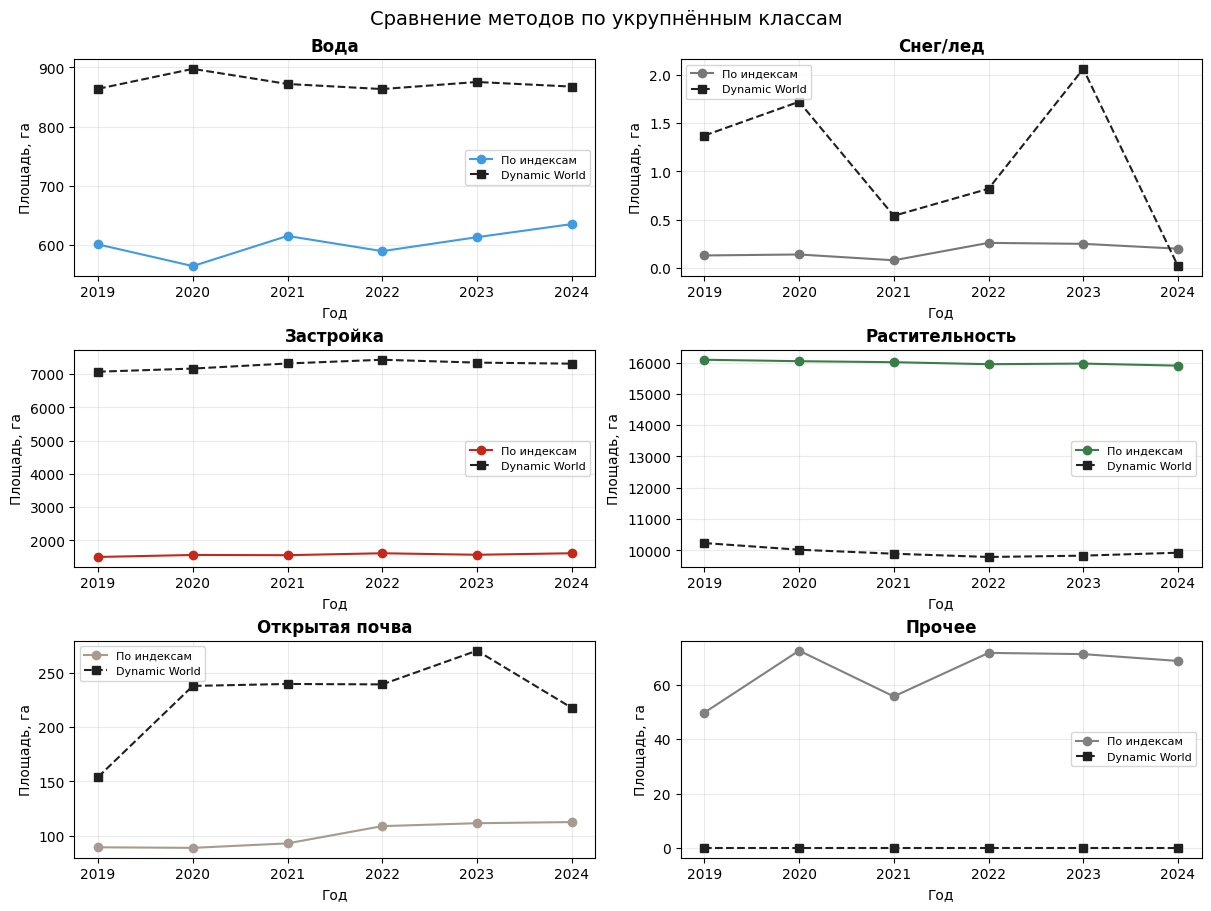

Матрица совпадений 2024 года: строки — индексы, столбцы — Dynamic World, пиксели.


,Вода,Снег/лед,Застройка,Растительность,Открытая почва,Прочее
Индексы / Dynamic World,,,,,,
Вода,63204,1,275,90,3,0
Снег/лед,14,0,3,3,0,0
Застройка,4800,0,133856,3596,18947,0
Растительность,16768,1,582247,989093,1863,0
Открытая почва,289,0,10119,28,814,0
Прочее,1696,0,5022,1,159,0


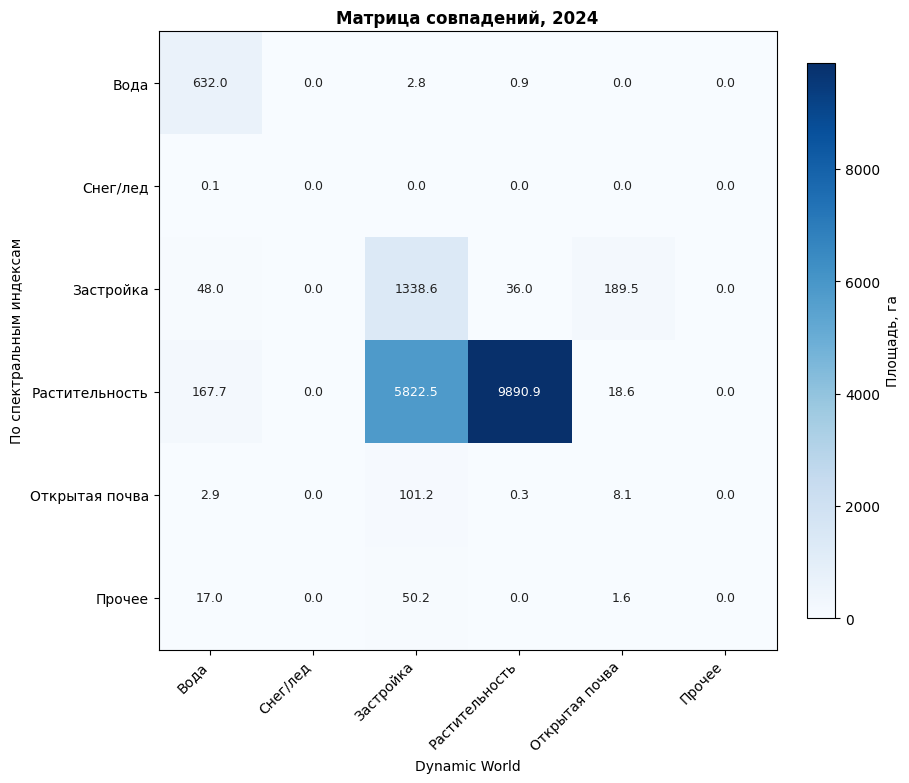

In [32]:
COARSE_NAMES = ['Вода', 'Снег/лед', 'Застройка', 'Растительность', 'Открытая почва', 'Прочее']
COARSE_COLORS = ['#419bdf', '#ffffff', '#c4281b', '#397d49', '#a59b8f', '#808080']
SEG_TO_COARSE = np.array([0, 1, 2, 3, 3, 3, 4, 5], dtype='int16')
DW_TO_COARSE = np.array([0, 3, 3, 3, 3, 3, 2, 4, 1], dtype='int16')


def remap_labels(labels, lookup):
    mapped = np.full(labels.shape, -1, dtype='int16')
    for code in range(len(lookup)):
        mapped[labels == code] = lookup[code]
    return mapped


seg_coarse = {}
dw_coarse = {}
for year in YEARS:
    seg_coarse[year] = remap_labels(segmented[year], SEG_TO_COARSE)
    dw_coarse[year] = remap_labels(dw_data[year], DW_TO_COARSE)
seg_coarse_area = count_pixels(seg_coarse, COARSE_NAMES, common_mask) * pixel_ha
dw_coarse_area = count_pixels(dw_coarse, COARSE_NAMES, common_mask) * pixel_ha
comparison_rows = []
agreement_rows = []
for year in YEARS:
    for name in COARSE_NAMES:
        comparison_rows.append({'Год': year, 'Класс': name,
                                'По индексам, га': seg_coarse_area.loc[name, year],
                                'Dynamic World, га': dw_coarse_area.loc[name, year],
                                'Разница, га': seg_coarse_area.loc[name, year] - dw_coarse_area.loc[name, year]})
    same_class = seg_coarse[year][common_mask] == dw_coarse[year][common_mask]
    agreement_percent = 100 * np.count_nonzero(same_class) / common_mask.sum()
    agreement_rows.append({'Год': year, 'Пиксели сравнения': int(common_mask.sum()),
                           'Совпадение, %': agreement_percent})
comparison = pd.DataFrame(comparison_rows).set_index(['Год', 'Класс'])
agreement = pd.DataFrame(agreement_rows).set_index('Год')
display(comparison.round(2))
display(agreement.round(2))
comparison.to_csv(RESULTS / 'coarse_area_comparison.csv', encoding='utf-8-sig')
agreement.to_csv(RESULTS / 'agreement_by_year.csv', encoding='utf-8-sig')
plot_dynamics(seg_coarse_area, COARSE_NAMES, COARSE_COLORS,
              'Сравнение методов по укрупнённым классам', 'methods_comparison.png', dw_coarse_area)

confusion_ha = transition_matrix(seg_coarse[2024], dw_coarse[2024], common_mask, COARSE_NAMES)
confusion_pixels = (confusion_ha / pixel_ha).round().astype('int64')
confusion_pixels.index.name = 'Индексы / Dynamic World'
print('Матрица совпадений 2024 года: строки — индексы, столбцы — Dynamic World, пиксели.')
display(confusion_pixels)
confusion_pixels.to_csv(RESULTS / 'confusion_2024_pixels.csv', encoding='utf-8-sig')
confusion_ha.to_csv(RESULTS / 'confusion_2024_ha.csv', encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(9, 8), layout='constrained')
im = ax.imshow(confusion_ha, cmap='Blues')
ax.set_xticks(range(6), COARSE_NAMES, rotation=45, ha='right')
ax.set_yticks(range(6), COARSE_NAMES)
ax.set_xlabel('Dynamic World')
ax.set_ylabel('По спектральным индексам')
ax.set_title('Матрица совпадений, 2024')
for i in range(6):
    for j in range(6):
        value = confusion_ha.iloc[i, j]
        if value > confusion_ha.to_numpy().max() / 2:
            text_color = 'white'
        else:
            text_color = '#222222'
        ax.text(j, i, f'{value:.1f}', ha='center', va='center',
                color=text_color, fontsize=9)
fig.colorbar(im, ax=ax, label='Площадь, га', shrink=0.8)
fig.savefig(FIGURES / 'confusion_2024.png', dpi=120)
plt.show()


## **9. Выводы**

В выводах обязательно отразить:
1. **Количественная оценка динамики** (с конкретными цифрами для каждого класса)
2. **Выявленные тренды** (растущие, убывающие, стабильные классы)
3. **Скорость изменений** (га/год и %/год для ключевых классов)
4. **Пространственные закономерности** (где происходят основные изменения)
5. **Согласованность методов** (доля совпадающих пикселей по укрупнённым классам в % и основные причины расхождений)

1. **Изменение площадей по индексам за 2019–2024 гг.**

   - Вода: 601.52 → 635.73 га; +34.21 га (+5.69%).
   - Снег/лед: 0.13 → 0.20 га; +0.07 га (+53.85%).
   - Застройка: 1500.15 → 1611.99 га; +111.84 га (+7.46%).
   - Густая растительность: 12178.91 → 12273.59 га; +94.68 га (+0.78%).
   - Умеренная растительность: 3015.97 → 2746.33 га; −269.64 га (−8.94%).
   - Разреженная растительность: 893.24 → 879.80 га; −13.44 га (−1.50%).
   - Открытая почва: 89.24 → 112.50 га; +23.26 га (+26.06%).
   - Прочее: 49.76 → 68.78 га; +19.02 га (+38.22%).

2. **Тренды.** По всем трём критериям задания устойчивый рост показала открытая почва. Классов с устойчивым снижением по этим критериям нет. Для воды, застройки и трёх классов растительности изменения не прошли пороги значимости. Снег/лед и прочее показали выраженные межгодовые колебания.

3. **Среднегодовые изменения ключевых классов.**

   - Вода: +6.84 га/год; +1.11%/год.
   - Застройка: +22.37 га/год; +1.45%/год.
   - Растительность в сумме: −37.68 га/год; −0.24%/год.
   - Открытая почва: +4.65 га/год; +4.74%/год.

4. **Расположение изменений.** Класс изменился на 3334.60 га, или 18.19% области анализа. Больше всего изменений в северо-западной части участка — 1064.18 га. Самый крупный переход: умеренная растительность → густая растительность, 949.04 га.

5. **Сравнение методов.** В 2024 году совпали 64.76% пикселей, среднее за шесть лет — 64.36%. Расхождения связаны с порогами индексов, смешением открытой почвы и застройки, а также с разным способом построения летних карт: медиана Sentinel-2 и мода Dynamic World. Это сравнение двух методов; наземная проверка здесь не проводилась.

Расчёты выполнены для общей области 183.29 км² — 99.95% выбранного участка. Смена метки класса может быть связана как с реальными изменениями, так и с различиями снимков и работой классификации.
